# [이론] LLM 라벨링 — 속성 코드북과 JSON 스키마

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 LLM 으로 라벨하는가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 비정형 데이터(자연어)</div>
<h1 style="color:#000000;margin:10px 0">LLM 라벨링 — 속성 코드북과 JSON 스키마</h1>
<div style="font-size:1.05em;color:#656565">별점으로는 보이지 않는 불만의 대상을 LLM 으로 리뷰마다 라벨하고 그 출력이 형식과 원문에 맞는지 확인합니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 리뷰의 불만은 어느 속성에 많은가 [필수]

**예시 리뷰 10건**은 어느 쇼핑몰의 텀블러 리뷰라고 가정한 가상의 예입니다.

| 번호 | 별점 | 리뷰 |
|---:|---:|---|
| 1 | 5 | 배송 빨라서 좋아요 |
| 2 | 2 | 배송은 빨랐는데 뚜껑이 새요 |
| 3 | 1 | 박스가 찢어져서 왔어요 |
| 4 | 2 | 생각보다 크기가 작아요 |
| 5 | 4 | 가격은 괜찮은데 손잡이가 약해요 |
| 6 | 1 | 환불 신청했는데 답이 없어요 |
| 7 | 1 | 좋아요 |
| 8 | 2 | 찌그러진 게 왔네요 |
| 9 | 1 | 색이 사진과 다르고 마감도 엉망이고 금방 깨졌어요 |
| 10 | 4 | 사은품도 챙겨 주셨어요 |

예시 리뷰 7 은 칭찬인데 1점이라 고객이 별점을 잘못 누른 것으로 가정합니다.

```text
별점 1 · 2점: 7건
별점 4 · 5점: 3건
별점 3점: 없음
```

별점으로는 1 · 2점 7건이 불만으로 보인다는 것까지만 압니다. 무엇이 불만인지는 본문을 읽어야 드러납니다. 리뷰가 많으면 사람이 다 읽기 어렵습니다.

그래서 토픽 이름 초안을 지을 때 쓴 LLM(대규모 언어 모델)에게 리뷰를 한 건씩 라벨하게 합니다. **라벨**은 리뷰가 평가한 대상(속성) 하나와 극성 하나의 짝입니다. 극성은 긍정 · 부정 · 중립 가운데 하나입니다. 「뚜껑이 새요」의 라벨은 (품질, 부정)입니다.

> 리뷰의 불만은 배송 · 품질 · 사이즈 같은 속성 가운데 어디에 많은가?

리뷰마다 (속성, 극성) 라벨을 달고 속성마다 부정 라벨이 있는 리뷰의 비율을 구합니다.

```text
예시 리뷰 10건
  ↓ LLM 이 리뷰마다 (속성, 극성) 라벨과 근거 텍스트(원문에서 그대로 옮긴 근거)를 냄
  ↓ 정해 둔 답의 형식(이름과 허용 값)을 지켰는지, 근거 텍스트가 원문에 있는지 확인
속성마다: 근거가 확인된 부정 라벨이 있는 리뷰 수 ÷ 보낸 리뷰 10건
```

<img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Rating_stars_2.0.svg" alt="별 다섯 개 가운데 두 개만 주황색으로 채워진 별점 그림" width="320" height="64" />
<p align="center"><em>▲ 별점 2.0. 리뷰 한 건의 별점은 수 하나다 (출처: Wikimedia Commons, Rating stars 2.0.svg, MRafizeldi, CC BY-SA 4.0)</em></p>

예시 리뷰 2 · 4 · 8 은 모두 별점 2점입니다. 그런데 불만은 리뷰마다 다릅니다.

- 리뷰 2 는 뚜껑이 샙니다. 배송이 빨랐다는 칭찬도 합니다.
- 리뷰 4 는 크기가 작습니다.
- 리뷰 8 은 무언가 찌그러져 왔습니다.

별점 2점 하나로는 이 차이가 보이지 않습니다.

LLM 이 낸 라벨을 집계하기 전에 뺄 라벨과 분모를 정합니다.

- 근거 텍스트가 원문에 없는 라벨은 집계에서 뺍니다. LLM 은 원문에 없는 구절을 지어낼 때가 있습니다.
- 분모는 LLM 에게 보낸 리뷰 수입니다. 형식을 끝내 지키지 못한 리뷰도 분모에 남기는데 그 이유는 「3. LLM 출력 검증」에서 봅니다.

이 수업에서 라벨에 쓴 LLM 은 오픈 모델(내려받아 직접 실행하는 모델) Qwen3-4B-Instruct-2507 입니다. 줄여서 Qwen3-4B 라고 부릅니다.

<div class="lms-summary">

**정리**

별점 하나로는 불만의 대상이 보이지 않습니다. 그래서 LLM 이 리뷰마다 (속성, 극성) 라벨과 근거 텍스트를 냅니다. 사람은 그 출력이 형식과 원문에 맞는지 확인한 뒤 집계합니다.

속성별 비율의 분모는 LLM 에게 보낸 리뷰 수입니다. 형식을 끝내 지키지 못한 리뷰도 분모에 남깁니다(「3. LLM 출력 검증」).

</div>

## 1. 속성 기반 감성 분석

별점 2점을 준 고객은 무엇이 싫었을까요? 리뷰가 평가한 대상(속성)마다 극성을 따로 구하면 보입니다. 어떤 표현을 어느 속성으로 볼지는 리뷰 속성 코드북에 정해 둡니다.

### 속성과 극성은 무엇인가 [필수]

리뷰 한 건 안에서도 좋았던 것과 싫었던 것이 갈립니다.

> 예시 리뷰 2(별점 2점): 「배송은 빨랐는데 뚜껑이 새요」

이 고객은 배송은 좋았고, 제품은 불만입니다.

**속성 기반 감성 분석(ABSA)** 은 리뷰가 평가한 대상마다 극성을 따로 구하는 분석입니다. 원어는 Aspect-Based Sentiment Analysis 입니다. AI Hub 의 데이터 이름처럼 「감정 분석」이라고도 씁니다. AI Hub 의 데이터 이름처럼 「감정 분석」이라고도 씁니다.

- **속성(aspect)** 은 리뷰가 평가한 대상입니다. 배송 · 품질 · 사이즈 같은 것입니다.
- **속성별 극성**은 속성 하나에 대해 구한 긍정 · 부정 · 중립입니다.

라벨 하나는 (속성, 극성) 한 쌍입니다. 예시 리뷰 2 에는 배송 긍정과 품질 부정, 라벨 2개가 있습니다.

예시 리뷰 5 「가격은 괜찮은데 손잡이가 약해요」의 라벨은 (가격, 긍정)과 (품질, 부정)입니다. **별점 극성**은 별점 1 · 2점을 부정, 4 · 5점을 긍정으로 본 값이라, 별점 4점인 이 리뷰는 긍정입니다. 품질 부정은 별점 극성과 반대지만, 리뷰의 일부에 대한 값이라 틀린 라벨이 아닙니다.

**별점과 비교하는 값은 무엇인가요?**

**리뷰 전체 극성**은 리뷰 한 건 전체가 좋았는지 나빴는지를 나타내는 값 하나입니다. 이 예처럼 비교할 별점에 3점이 없으면 중립을 두지 않아, 값은 긍정 · 부정 둘뿐입니다.

예시 리뷰 7 「좋아요」는 무엇이 좋은지 말하지 않은 감탄이라 속성이 없습니다. 그래서 라벨은 없고, 리뷰 전체 극성 「긍정」에만 반영됩니다.

| | 속성별 극성 | 리뷰 전체 극성 |
|---|---|---|
| 리뷰 한 건에 몇 개 | 여럿, 없을 수도 있다 | 하나 |
| 값 | 긍정 · 부정 · 중립 | 긍정 · 부정 |
| 예시 리뷰 2 | 배송 긍정 · 품질 부정 | 부정 |
| 예시 리뷰 7 | 없음 | 긍정 |
| 쓰는 곳 | 불만의 대상 찾기 | 별점 극성과 일치하는지 확인 |

따라서 불만의 대상은 속성별 극성으로 찾고, 리뷰 전체 극성은 별점과 비교할 때 씁니다.

**LLM 은 리뷰마다 무엇을 출력하나요?**

속성 기반 감성 분석의 개관 논문은 한 문장의 분석 결과를 대상 단어 · 속성 · 의견 단어 · 극성으로 나눕니다.

<img src="https://ar5iv.labs.arxiv.org/html/2203.01054/assets/overview.png" alt="문장 The pizza is delicious 를 속성 기반 감성 분석 시스템이 받아 Aspect Term pizza, Aspect Category food, Opinion Term delicious, Sentiment Polarity POS 네 행의 표로 출력하는 그림" width="620" height="250" />
<p align="center"><em>▲ 속성 기반 감성 분석의 출력. 문장 「The pizza is delicious」가 분석 시스템을 거쳐 4가지 값의 표가 된다 (출처: Zhang 외, 「A Survey on Aspect-Based Sentiment Analysis」, arXiv:2203.01054, Fig. 1)</em></p>

이 수업에서는 대상 단어를 뺀 나머지 값을 LLM 에게서 받습니다.

| 개관 논문의 이름 | 이 수업에서 받는 값 | 예시 리뷰 2 의 품질 라벨 |
|---|---|---|
| Aspect Term(대상 단어, pizza) | 받지 않음(속성 이름으로 대신) | (받는다면 「뚜껑」) |
| Aspect Category(속성, food) | 속성 | 품질 |
| Opinion Term(의견 단어, delicious) | 근거 텍스트 | 「뚜껑이 새요」 |
| Sentiment Polarity(극성, POS) | 속성별 극성 | 부정 |

**근거 텍스트**(evidence)는 라벨을 정한 근거로 원문에서 글자 그대로 옮긴 짧은 텍스트입니다. 예시 리뷰 2 의 (배송, 긍정)이라면 「배송은 빨랐는데」입니다.

원문을 고치지 않고 옮겨야 사람이 나중에 라벨을 원문과 대조할 수 있습니다.

따라서 LLM 은 리뷰 한 건마다 라벨 여럿과 리뷰 전체 극성 하나를 냅니다. 라벨마다 근거 텍스트가 함께 나옵니다. 예시 리뷰 7 처럼 라벨이 하나도 없을 수 있습니다.

### 리뷰 속성 코드북 [필수]

LLM 에게 속성을 맡기려면 어떤 표현을 어느 속성으로 볼지 먼저 정해야 합니다. 「뚜껑이 새요」를 품질로 보는 것도 정해 둔 기준입니다.

**리뷰 속성 코드북**은 속성마다 이름 · 정의 · 포함 기준 · 제외 기준 · 예를 적은 표입니다. 토픽 검증 때의 코드북(「5. 코드북」)처럼, 누가 나눠도 같은 리뷰에 같은 라벨이 나오게 합니다.

**두 코드북은 무엇이 다른가요?**

| | 토픽 검증 때의 코드북 | 리뷰 속성 코드북 |
|---|---|---|
| 이름 | 토픽을 모은 뒤 원문을 읽고 짓는다 | 속성 이름을 먼저 정하고 리뷰마다 고른다 |
| 한 건에 다는 것 | 민원 한 건에 테마 하나 | 리뷰 한 건에 라벨 여럿, 라벨마다 극성 |
| 원인 항목 | 있다 | 두지 않는다. 무엇을 평가했는지만 다룬다 |
| 기타 | 어느 테마에도 속하지 않는 민원 | 판매자 응대 · 사은품 같은 구체적 평가의 속성 |

기타의 뜻이 가장 헷갈립니다. 예시 리뷰 10 「사은품도 챙겨 주셨어요」는 사은품을 평가해 (기타, 긍정)입니다. 예시 리뷰 7 「좋아요」는 무엇이 좋은지 말하지 않은 감탄이라 기타가 아니라 라벨이 없습니다.

배송 · 품질 · 사이즈 · 가격 · 교환/환불 5개는 리뷰 토픽을 근거로 정했습니다. 근거가 된 토픽 표는 「6. 리뷰 1,000건 라벨 결과와 팀 라운드」에 있습니다. 그 밖의 구체적 평가는 기타 속성에 모읍니다.

**리뷰 속성 코드북 v1** 은 속성 6개로 쓴 첫 코드북입니다.

| 속성 | 정의 | 포함 기준 | 제외 기준 | 예 |
|---|---|---|---|---|
| 배송 | 주문한 물건이 도착하기까지의 과정 | 속도·지연, 택배, 포장·박스 상태, 오배송 | 제품 자체의 흠집·불량(→ 품질) | 「배송 빨라서 좋아요」 · 「박스가 찢어져서 왔어요」 |
| 품질 | 제품 자체의 상태와 성능 | 불량, 마감, 내구성, 맛·신선도, 성능, 디자인 | 크기·치수(→ 사이즈), 포장 상태(→ 배송) | 「뚜껑이 새요」 · 「손잡이가 약해요」 |
| 사이즈 | 크기·길이·치수가 맞는지 | 크기, 길이, 핏, 양 | 무게감·두께 같은 재질 느낌(→ 품질) | 「생각보다 크기가 작아요」 |
| 가격 | 값과 가성비 | 싸다·비싸다, 가성비, 할인 | 환불 금액(→ 교환/환불) | 「가격은 괜찮은데」 |
| 교환/환불 | 교환·반품·환불·취소 절차 | 교환·반품, 환불, 주문 취소 | 처음 배송 지연(→ 배송) | 「환불 신청했는데 답이 없어요」 |
| 기타 | 위 속성 어디에도 속하지 않는 구체적 평가 | 판매자 응대, 사은품 등 | 속성이 드러나지 않는 감탄(예: 좋아요)은 라벨을 달지 않음 | 「사은품도 챙겨 주셨어요」 |

배송과 품질은 무엇이 파손됐는지로 나뉩니다. 같은 파손이라도 박스가 찢어진 예시 리뷰 3 은 배송이고 제품이 금방 깨진 예시 리뷰 9 는 품질입니다.

예시 리뷰 10건에 코드북 v1 을 적용하면 아래 라벨이 나옵니다. 리뷰마다 라벨을 먼저 정해 본 뒤 표와 비교해 봅니다.

| 번호 | 리뷰 | 코드북 v1 로 정한 라벨 |
|---:|---|---|
| 1 | 배송 빨라서 좋아요 | (배송, 긍정) |
| 2 | 배송은 빨랐는데 뚜껑이 새요 | (배송, 긍정) · (품질, 부정) |
| 3 | 박스가 찢어져서 왔어요 | (배송, 부정) |
| 4 | 생각보다 크기가 작아요 | (사이즈, 부정) |
| 5 | 가격은 괜찮은데 손잡이가 약해요 | (가격, 긍정) · (품질, 부정) |
| 6 | 환불 신청했는데 답이 없어요 | (교환/환불, 부정) |
| 7 | 좋아요 | 없음 |
| 8 | 찌그러진 게 왔네요 | 정할 수 없음 |
| 9 | 색이 사진과 다르고 마감도 엉망이고 금방 깨졌어요 | (품질, 부정) 3개 |
| 10 | 사은품도 챙겨 주셨어요 | (기타, 긍정) |

- 예시 리뷰 9 의 세 구절은 모두 품질입니다. 색은 디자인, 마감은 마감, 깨짐은 내구성이라 모두 품질의 포함 기준에 있습니다.
- 예시 리뷰 8 은 코드북 v1 로는 속성을 정할 수 없습니다.

**코드북 v1 로 정할 수 없는 리뷰는 어떻게 하나요?**

**애매한 리뷰**는 원문만으로는 속성이 하나로 정해지지 않는 리뷰입니다. 예시 리뷰 8 「찌그러진 게 왔네요」는 박스가 찌그러졌다면 배송이고, 제품이 찌그러졌다면 품질입니다.

토픽 검증 때의 애매한 민원처럼 어느 속성으로 볼지 분석가가 정합니다. 그 결정은 고른 속성의 포함 기준이나 다른 속성의 제외 기준에 들어갑니다. 여기서는 품질로 보고 품질의 포함 기준에 다음 내용을 더합니다.

> 파손 대상이 원문에 없으면 품질.

이제 예시 리뷰 8 은 (품질, 부정)입니다. 배송으로 정해도 되지만 어느 쪽이든 코드북에 있어야 같은 표현이 늘 같은 속성으로 분류됩니다.

**버전**은 분석가가 코드북 · 프롬프트를 고칠 때마다 새로 정하는 이름(v1, v2)입니다. 코드북 v2 는 품질의 포함 기준에 이 내용을 더한 코드북입니다. 코드북은 프롬프트의 일부라서 프롬프트의 버전도 함께 바뀝니다. 그래서 라벨 결과에는 어느 버전으로 낸 라벨인지 기록합니다.

예시 리뷰 2 는 별점은 하나인데 라벨이 2개입니다. 두 라벨의 근거 텍스트가 원문의 어디인지 아래 그림에서 봅니다.

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/d6-review-evidence.png" alt="예시 리뷰 2 「배송은 빨랐는데 뚜껑이 새요」의 원문 한 줄. 앞 구절 「배송은 빨랐는데」는 하늘색 바탕에 배송 · 긍정, 뒤 구절 「뚜껑이 새요」는 회색 바탕에 품질 · 부정이 위에 적혀 있다. 두 구절 아래를 하나로 잇는 선에 별점 2점은 리뷰 전체에 점수 하나라고 적혀 있다" width="830" height="251" />
<p align="center"><em>▲ 가상의 예다. 하늘색 바탕은 별점 극성과 반대인 라벨의 근거 텍스트이고, 회색 바탕은 별점 극성과 일치하는 라벨의 근거 텍스트이다. 아래 선은 별점이 리뷰 전체에 걸린 점수라는 표시다</em></p>

예시 리뷰 2 의 별점 2점만 보면 이 고객이 배송에 만족했는지 알 수 없습니다.

**다중 라벨**은 리뷰 한 건에 라벨을 여럿 다는 방식입니다. 코드북 v2 로 정한 예시 리뷰 10건의 라벨은 13개이고 라벨이 둘 이상인 리뷰는 3건입니다.

- 예시 리뷰 2 · 5: 서로 다른 속성의 라벨 2개, 극성도 서로 반대
- 예시 리뷰 9: 색 · 마감 · 깨짐마다 (품질, 부정) 라벨이 하나씩, 모두 3개

그래서 속성마다 비율을 구해 더하면 100% 를 넘을 수 있습니다. 긍정 · 부정 라벨을 모두 포함해 속성마다 그 속성의 라벨이 있는 리뷰 수를 구했습니다.

| 속성 | 배송 | 품질 | 사이즈 | 가격 | 교환/환불 | 기타 | 합 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 라벨이 있는 리뷰 | 3 | 4 | 1 | 1 | 1 | 1 | 11 |

예시 리뷰 9 에는 품질 라벨이 3개 있지만 품질 라벨이 있는 리뷰로는 한 건이라 합은 라벨 수보다 2 적은 11건입니다. 이 합은 리뷰 10건의 110% 입니다.

<div class="lms-summary">

**정리**

불만의 대상은 리뷰마다 (속성, 극성) 라벨로 나눠야 보입니다. LLM 은 라벨마다 근거 텍스트를, 리뷰마다 리뷰 전체 극성을 함께 냅니다. 어떤 표현을 어느 속성으로 볼지는 리뷰 속성 코드북의 포함 기준과 제외 기준으로 정합니다.

**할 일**

- 속성마다 이름 · 정의 · 포함 기준 · 제외 기준 · 예를 코드북에 적습니다
- 애매한 리뷰는 어느 속성으로 볼지 정하고 그 속성의 포함 기준이나 다른 속성의 제외 기준에 그 결정을 추가합니다
- 기준을 고친 코드북에는 새 버전 이름을 정합니다

리뷰 한 건에 라벨이 여럿일 수 있어, 속성별 비율은 더해도 100% 가 되지 않습니다.

</div>

> **[문제] 별점 2점 리뷰 「택배는 빨리 왔는데 사이즈가 너무 커요」를 리뷰 속성 코드북 v1 으로 나눈 (속성, 극성) 라벨로 맞는 것은 무엇일까요?**
>
> 1. 별점이 2점이므로 (배송, 부정) · (사이즈, 부정)
> 2. (사이즈, 부정) 라벨 1개. 별점과 같은 쪽만 적는다
> 3. (배송, 긍정) · (사이즈, 부정)
> 4. (배송, 긍정) · (품질, 부정). 크기가 맞지 않는 것은 제품 불량이다

## 2. 코드북을 JSON 스키마로

리뷰마다 받은 라벨을 표 하나로 모으려면, LLM 의 답을 어떤 형식으로 받아야 할까요?

필드 이름과 허용 값이 정해진 JSON 으로 받습니다. 필드와 허용 값은 JSON 스키마로 정하고, 코드북의 속성 6개가 속성 필드의 허용 값이 됩니다.

### JSON 스키마는 무엇을 정하는가 [필수]

사람에게 설명하듯 자유 문장으로 받으면 리뷰마다 문장 형식이 다릅니다. 그러면 속성과 극성을 표의 열로 옮길 수 없습니다.

**JSON**(JavaScript Object Notation)은 중괄호 안에 「이름: 값」을 쉼표로 나열한 텍스트 형식입니다. **필드** 는 「이름: 값」 하나입니다. 값으로 목록이나 또 다른 중괄호가 올 수 있습니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/5/5e/Example_json_code.png" alt="JSON 글자 아래에 endereco 라는 이름의 중괄호 안에 cep, city, neighborhood, service, state, street 의 키와 값 여섯 개가 있는 코드" width="520" height="298" />
<p align="center"><em>▲ JSON 한 건. 중괄호 안에 "이름": 값 필드가 쉼표로 이어지고, endereco 의 값은 또 다른 중괄호다 (출처: Wikimedia Commons, Example json code.png, Dcbmarian, CC BY 4.0)</em></p>

예시 리뷰 5 「가격은 괜찮은데 손잡이가 약해요」에 LLM 이 낸 출력이 아래 JSON 한 건이라고 해 봅니다.

```text
{"overall": "긍정",
 "aspects": [
   {"aspect": "가격", "polarity": "긍정", "evidence": "가격은 괜찮은데"},
   {"aspect": "품질", "polarity": "부정", "evidence": "손잡이가 약해요"}
 ]}
```

- 바깥 중괄호에는 필드 `overall` 과 `aspects` 2개가 있습니다.
- `aspects` 의 값은 대괄호 안의 목록이고, 목록의 항목 하나가 라벨 하나입니다.
- 라벨마다 속성 `aspect`, 극성 `polarity`, 근거 텍스트 `evidence` 의 필드 3개가 있습니다.

필드 이름이 정해져 있으면 리뷰마다 값을 꺼내 표로 모을 수 있습니다. 예시 리뷰 5 의 라벨 2개는 표의 행 2개가 됩니다.

| 리뷰 | overall | aspect | polarity | evidence |
|---|---|---|---|---|
| 예시 리뷰 5 | 긍정 | 가격 | 긍정 | 가격은 괜찮은데 |
| 예시 리뷰 5 | 긍정 | 품질 | 부정 | 손잡이가 약해요 |

다만 필드 이름이나 값이 리뷰마다 다르면 JSON 이어도 표로 모을 수 없습니다. 바이브 데이터 분석 과목에서 데이터 품질을 볼 때 쓴 **스키마** 는 데이터가 따라야 할 구조와 표기의 약속입니다. LLM 출력에도 이 약속을 정하고 확인합니다.

**JSON 스키마(JSON Schema)** 는 출력에 반드시 있어야 할 필드와, 필드마다 허용되는 값을 정한 형식입니다. **enum**(enumeration)은 한 필드에 허용하는 값을 모두 나열한 목록입니다.

| 필드 | 뜻 | 허용 값(enum) |
|---|---|---|
| `overall` | 리뷰 전체 극성 | 긍정 · 부정 |
| `aspects` | 라벨의 목록 | 목록, 비어도 됨 |
| `aspect` | 속성 | 코드북의 속성 6개 |
| `polarity` | 속성별 극성 | 긍정 · 부정 · 중립 |
| `evidence` | 근거 텍스트 | 목록 없음, 문자열이면 됨 |

아래 실행 셀의 `SCHEMA_V1` 이 이 표를 코드로 옮긴 스키마입니다. `schema_errors` 는 스키마에 맞지 않는 곳을 문장 목록으로 내고, 빈 목록이면 통과입니다. 예시 리뷰 5 의 출력과 예시 리뷰 9 의 첫 출력을 검사해 봅니다.

In [ ]:
# 리뷰 속성 코드북 v1 의 스키마(LLM 출력을 확인할 때 쓰는 dict)
ASPECTS = ["배송", "품질", "사이즈", "가격", "교환/환불", "기타"]
SCHEMA_V1 = {
    "type": "object",
    "required": ["overall", "aspects"],
    "properties": {
        "overall": {"enum": ["긍정", "부정"]},                       # 리뷰 전체 극성
        "aspects": {
            "type": "array",
            "items": {
                "type": "object",
                "required": ["aspect", "polarity", "evidence"],
                "properties": {
                    "aspect": {"enum": ASPECTS},                     # 속성: 코드북의 속성 6개
                    "polarity": {"enum": ["긍정", "부정", "중립"]},   # 속성별 극성
                    "evidence": {"type": "string"},                  # 근거 텍스트: 원문에서 그대로
                },
            },
        },
    },
}


def schema_errors(obj, schema=SCHEMA_V1):
    # 스키마에 맞지 않는 곳을 문장 목록으로 반환한다(빈 목록이면 통과)
    errs = []

    def walk(x, sch, path):
        if "enum" in sch:                                            # 허용 값 목록이 있는 필드
            if x not in sch["enum"]:
                errs.append(f"{path} 값 {x!r} — 허용 목록 밖")
            return
        if sch.get("type") == "object":
            for k in sch.get("required", []):                        # 필수 필드가 있는가
                if k not in x:
                    errs.append(f"{path}.{k} 없음")
            for k, sub in sch.get("properties", {}).items():
                if k in x:
                    walk(x[k], sub, f"{path}.{k}")
        elif sch.get("type") == "array":
            for i, item in enumerate(x):
                walk(item, sch["items"], f"{path}[{i}]")
        elif sch.get("type") == "string" and not isinstance(x, str):
            errs.append(f"{path} 는 문자열이어야 함")

    walk(obj, schema, "$")
    return errs


# 예시 리뷰 5 「가격은 괜찮은데 손잡이가 약해요」의 출력(가상의 예)
out_5 = {"overall": "긍정",
         "aspects": [{"aspect": "가격", "polarity": "긍정", "evidence": "가격은 괜찮은데"},
                     {"aspect": "품질", "polarity": "부정", "evidence": "손잡이가 약해요"}]}
# 예시 리뷰 9 「색이 사진과 다르고 마감도 엉망이고 금방 깨졌어요」의 첫 출력(가상의 예)
out_9_first = {"overall": "부정",
               "aspects": [{"aspect": "디자인", "polarity": "부정", "evidence": "색이 사진과 다르고"},
                           {"aspect": "품질", "polarity": "부정", "evidence": "마감도 엉망이고"},
                           {"aspect": "품질", "polarity": "부정", "evidence": "금방 깨졌어요"}]}
print("예시 리뷰 5 출력의 오류:", schema_errors(out_5))
print("예시 리뷰 9 첫 출력의 오류:", schema_errors(out_9_first))

**스키마 검증은 무엇을 걸러 내나요?**

- 예시 리뷰 5 의 출력은 값이 모두 허용 값 안이라 오류 목록이 비어 있습니다.
- 예시 리뷰 9 의 첫 출력은 색에 대한 라벨의 속성을 「디자인」으로 썼습니다. 「허용 목록 밖」 오류가 하나 나옵니다.

색은 품질의 포함 기준 「디자인」에 속하는 말이라, 이 라벨의 속성은 품질이어야 합니다. 디자인은 포함 기준의 단어이지 속성 이름이 아닙니다. 스키마 검증은 이런 값을 표로 모으기 전에 걸러 냅니다.

오류 문장의 `$` 는 출력 전체, `[0]` 은 목록의 첫 항목입니다. `$.aspects[0].aspect` 는 첫 라벨의 속성입니다.

<details class="lms-extra"><summary>자세히 — SCHEMA_V1 의 키 5개</summary>

| 키 | 뜻 |
|---|---|
| `type` | 값의 종류. object 는 중괄호, array 는 목록, string 은 문자열 |
| `required` | 반드시 있어야 하는 필드의 이름 |
| `properties` | 필드마다 정한 조건 |
| `items` | 목록 안 항목 하나의 형식 |
| `enum` | 허용 값 목록 |

`type` 이 object 인 값은 중괄호 하나이고 그 안에 올 필드는 `properties` 로 정해집니다. 위 JSON 그림의 endereco 처럼 값이 또 다른 중괄호이면, 그 값에도 object 조건을 한 번 더 적용합니다.

`SCHEMA_V1` 에서는 `aspects` 의 `items` 가 그런 예입니다. 목록 안 항목 하나가 다시 중괄호이고 그 안에 `aspect` · `polarity` · `evidence` 필드 3개가 있습니다.

</details>

근거 텍스트는 문자열이기만 하면 스키마를 통과합니다. 그래서 모델에게는 근거 텍스트를 고치거나 요약하지 않고 원문에서 글자 그대로 옮기라고 지시합니다.

overall · aspect · polarity 는 허용 값 안인지만 보면 되지만 근거 텍스트는 원문과 대조해야 확인됩니다.

**스키마와 코드북은 모델에게 어떻게 전하나요?**

**시스템 프롬프트** 에 함께 씁니다. 시스템 프롬프트는 요청마다 리뷰 앞에 오는 고정 지시문입니다. 라벨을 받는 시스템 프롬프트는 대개 코드북 · 지시 · 예 하나로 구성합니다.

| 부분 | 내용 |
|---|---|
| 코드북 | 속성 6개의 이름 · 정의 · 포함 기준 · 제외 기준 |
| 지시 | 스키마를 말로 쓴 부분. overall 은 긍정 · 부정, polarity 는 긍정 · 부정 · 중립, evidence 는 원문 그대로, 속성이 없으면 빈 목록, JSON 한 개만 답할 것 |
| 예 하나 | 리뷰 한 건과 그 리뷰의 JSON |

코드북 부분에는 제외 기준(그 속성이 아닌 표현과 보낼 속성, 예: 박스 파손 → 배송)도 포함합니다. 제외 기준이 없으면 박스 파손처럼 두 속성에 걸치는 표현을 LLM 이 리뷰마다 다르게 나눌 수 있습니다.

시스템 프롬프트는 요청마다 같고 리뷰만 바뀝니다.

```text
요청 1번 = 시스템 프롬프트(요청마다 같음) + 「리뷰: …」 1건(요청마다 바뀜)
```

### 같은 리뷰에 늘 같은 라벨이 나오는가 [필수]

라벨로 비율을 내려면 같은 리뷰에는 늘 같은 라벨이 나와야 합니다. 호출할 때마다 라벨이 바뀌면 비율도 바뀝니다.

**temperature** 는 토큰 점수(로짓, logit)를 확률로 바꾸기 전에 점수를 나누는 수입니다. 확률은 점수를 소프트맥스로 바꿔 구합니다. 토픽 검증 때의 「3. LLM 으로 토픽 이름 초안 만들기」에서도 이 값을 썼습니다.

temperature 를 0 쪽으로 내릴수록 1위 토큰의 확률이 1 에 가까워집니다. temperature 0 은 1위 토큰을 바로 고르는 것으로 정하므로, 같은 입력에 같은 출력이 나옵니다. 라벨도 temperature 0 으로 받습니다.

**temperature 0 이면 언제나 같은 라벨이 나오나요?**

입력과 모델이 그대로일 때만 그렇습니다. 프롬프트나 모델이 바뀌면 같은 리뷰에도 다른 라벨이 나올 수 있습니다. 그래서 무엇으로 라벨했는지를 버전으로 남깁니다.

코드북 · 프롬프트의 버전은 분석가가 고칠 때마다 새로 정하는 이름입니다(「1. 속성 기반 감성 분석」). 예를 들어 코드북 v2 에서는 예시 리뷰 8 「찌그러진 게 왔네요」가 품질로 정해집니다. v1 으로 라벨했을 때와 라벨이 달라질 수 있습니다.

**모델 버전** 은 공급자가 모델 파일마다 정한 식별자입니다. 모델 파일을 내려받을 때 기록되는 cdbee75f 같은 문자열이 그 예입니다. 모델 이름 Qwen3-4B-Instruct-2507 의 2507 은 버전이 아니라 이름의 일부입니다. 모델 이름이 같아도 모델 파일이 바뀌면 모델 버전이 달라지고 같은 리뷰의 라벨도 바뀔 수 있습니다.

**결과 파일에는 무엇을 기록하나요?**

모델 이름 · 모델 버전 · 프롬프트 버전을 기록합니다. 두 결과의 비율이 다를 때, 리뷰가 달라서인지 라벨 방법이 바뀌어서인지 구별하려는 것입니다.

기기(GPU 종류)가 바뀌어도 몇 건은 바뀔 수 있습니다. 컴퓨터는 소수를 정해진 자릿수에서 반올림하며 더하므로, 더하는 순서가 다르면 마지막 자릿수가 조금 달라집니다. 기기마다 더하는 순서가 달라 점수가 조금 바뀝니다. 1위와 2위 점수가 거의 같은 리뷰는 이 차이로 고르는 토큰이 바뀝니다. 그래서 기기를 바꾸면 같은 리뷰 몇 건을 다시 라벨해 비교합니다.

<div class="lms-summary">

**정리**

코드북의 속성 6개가 JSON 스키마의 허용 값이 됩니다. 스키마 검증은 예시 리뷰 9 의 「디자인」 같은 허용 목록 밖의 값을 걸러 냅니다. 근거 텍스트는 문자열인지만 검사되므로 원문 대조가 따로 필요합니다.

**할 일**

- 시스템 프롬프트에는 제외 기준까지 포함한 코드북과 스키마를 말로 옮긴 지시, 예 하나를 씁니다
- 결과 파일에 모델 이름 · 모델 버전 · 프롬프트 버전을 기록합니다

라벨은 temperature 0 으로 받지만 프롬프트나 모델이 바뀌면 같은 리뷰의 라벨도 바뀔 수 있습니다.

</div>

> **[문제] 결과 파일에 버전을 기록하는 이유**
>
> 같은 리뷰 10건을 temperature 0 으로 두 번 라벨했더니 두 번 모두 라벨이 같았습니다. 그런데 다음 분기에 같은 10건을 다시 라벨하니 2건의 라벨이 달라졌습니다. 무엇이 바뀌었을 수 있는지와, 두 분기의 비율을 비교하려면 결과 파일에 무엇을 기록해야 하는지 두세 문장으로 적어 보세요.

## 3. LLM 출력 검증

스키마를 프롬프트에 적고 「JSON 한 개만 답하라」고 지시하면, 출력이 늘 그 형식을 따를까요?

그렇지 않습니다. 그래서 출력마다 형식과 근거 텍스트를 4단계로 확인하고, 끝내 통과하지 못한 리뷰도 분모에 남겨 비율을 구합니다.

### 검증 4단계 [필수]

**왜 형식을 어길 수 있나요?**

LLM 은 답을 토큰 하나씩 이어 쓸 뿐이고 생성 과정에는 스키마를 확인하는 단계가 없습니다. 프롬프트의 스키마는 입력의 일부일 뿐이라, 출력이 그 형식을 지킨다는 보장이 없습니다.

그래서 중괄호를 닫지 않은 채 끝나거나, 허용 목록 밖의 단어를 쓴 출력이 나옵니다. 형식은 생성이 끝난 뒤 코드로 확인합니다.

- ① **파싱**: 출력에서 중괄호 `{…}` 로 묶인 부분을 찾아 JSON 으로 읽습니다.
- ② **스키마 검증**(schema validation): 읽은 JSON 에 필수 필드가 모두 있고 값이 허용 목록 안인지 봅니다. 앞의 `schema_errors` 가 이 일을 합니다.
- ③ **어긴 출력만 재시도**(retry): ①이나 ②에서 실패한 출력만 오류 목록과 함께 한 번 더 묻습니다.
- ④ **근거 텍스트 확인**: 통과한 출력도 라벨마다 근거 텍스트가 원문에 그대로 있는지 봅니다.

③에서는 아래 문장을 보냅니다. `{errors}` 는 `schema_errors` 가 찾은 오류 문장으로 바뀝니다.

```text
위 답은 규칙에 맞지 않습니다({errors}). 규칙에 맞는 JSON 한 개만 다시 답하세요.
```

예시 리뷰 10건에서는 첫 시도에 2건이 형식을 어기고 재시도 뒤에도 1건이 남습니다.

```text
보낸 리뷰 10건(코드북 v2 로 라벨한다고 가정)
  ↓ ① 파싱 · ② 스키마 검증
첫 시도 통과 8건 · 어긴 2건(예시 리뷰 6 · 9)
  ↓ ③ 어긴 2건만 한 번 재시도
통과 1건(예시 리뷰 9) · 라벨 실패 1건(예시 리뷰 6)
→ 통과한 리뷰 9건, 라벨 12개
   (코드북 v2 의 라벨 13개 − 라벨 실패인 예시 리뷰 6 의 1개)
  ↓ ④ 근거 텍스트 확인
근거 확인 11개 · 보류 1개(예시 리뷰 2 의 품질 부정)
```

- 예시 리뷰 6 의 출력은 라벨 항목의 중괄호를 닫지 않아 ①에서 실패합니다. 재시도한 출력도 파싱에 실패합니다.
- 예시 리뷰 9 의 첫 출력은 「디자인」 때문에 ②에서 실패합니다. 재시도한 출력은 (품질, 부정) 3개로 통과합니다.
- 예시 리뷰 2 의 출력은 형식을 통과하지만 품질 부정의 근거 텍스트가 원문에 없어 ④에서 걸립니다.

**라벨 실패** 는 재시도 뒤에도 출력이 형식을 통과하지 못한 리뷰입니다(리뷰 단위). 버리지 않고 분모에 남깁니다.

**보류** 는 근거 텍스트가 원문에 없어 집계에서 뺀 라벨입니다(라벨 단위). 그 리뷰는 분모에 남습니다. 보류한 라벨은 지우지 않고 남겨 사람이 원문을 읽고 판단합니다.

**근거 텍스트가 원문에 있는지는 어떻게 확인하나요?**

**부분 문자열** 은 원문 안에 글자 그대로 이어져 있는 일부분입니다. 근거 텍스트가 원문의 부분 문자열인지 보고, 공백이 여러 개 이어진 곳만 하나로 줄인 뒤 비교합니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/3/3f/Substring.png" alt="단어 substring 가운데 뒤쪽 string 여섯 글자를 하늘색으로 칠하고 아래에 괄호를 그은 그림" width="420" height="257" />
<p align="center"><em>▲ 부분 문자열. 「substring」 안에 「string」 여섯 글자가 끊기지 않고 이어져 있다 (출처: Wikimedia Commons, Substring.png, CC0)</em></p>

> 원문: 「배송은 빨랐는데 뚜껑이 새요」
>
> 품질 부정의 근거 텍스트: 「뚜껑이 샌다」

뜻은 같지만 「뚜껑이 샌다」는 원문의 어미를 고친 글이라 원문 안에 없습니다. 그래서 예시 리뷰 2 의 품질 부정은 보류됩니다.

아래 셀은 예시 리뷰 2 와 9 의 출력 JSON 을 읽어 근거 텍스트를 원문과 대조합니다.

In [ ]:
# LLM 이 낸 JSON 을 읽고, 근거 텍스트가 원문 안에 글자 그대로 이어져 있는지 확인한다
# (예시 리뷰 2 의 출력과 예시 리뷰 9 의 재시도 출력은 가상의 예)
import json
import re


def squeeze(s):                                  # 공백이 여러 개 이어진 곳만 하나로 줄인다
    return re.sub(r"\s+", " ", s).strip()


text_2 = "배송은 빨랐는데 뚜껑이 새요"
out_2 = ('{"overall": "부정", "aspects": ['
         '{"aspect": "배송", "polarity": "긍정", "evidence": "배송은 빨랐는데"}, '
         '{"aspect": "품질", "polarity": "부정", "evidence": "뚜껑이 샌다"}]}')
text_9 = "색이 사진과 다르고 마감도 엉망이고 금방 깨졌어요"
out_9 = ('{"overall": "부정", "aspects": ['
         '{"aspect": "품질", "polarity": "부정", "evidence": "색이 사진과 다르고"}, '
         '{"aspect": "품질", "polarity": "부정", "evidence": "마감도 엉망이고"}, '
         '{"aspect": "품질", "polarity": "부정", "evidence": "금방 깨졌어요"}]}')

for rid, text, out in [(2, text_2, out_2), (9, text_9, out_9)]:
    for a in json.loads(out)["aspects"]:
        found = squeeze(a["evidence"]) in squeeze(text)
        print(f"예시 리뷰 {rid} · ({a['aspect']}, {a['polarity']}) · 근거 텍스트 「{a['evidence']}」 · 원문에 있음: {found}")

실행 결과에서 예시 리뷰 2 의 품질 부정 근거 텍스트 「뚜껑이 샌다」만 False 입니다. 같은 리뷰의 (배송, 긍정)은 근거 텍스트가 원문에 있어 그대로 집계에 씁니다. 예시 리뷰 9 의 근거 텍스트 3개는 모두 True 입니다.

예시 리뷰 2 의 출력은 ② 스키마 검증을 통과한 출력입니다. 스키마는 `evidence` 가 문자열인지만 검사해, 원문에 없는 근거 텍스트는 ④에서야 걸러집니다.

<details class="lms-extra"><summary>더 깊이 — API 의 구조화된 출력과 제약된 디코딩</summary>

API 는 공급자의 서버에 요청을 보내 모델을 호출하는 방식입니다. API 로 모델을 호출하면 **구조화된 출력(Structured Outputs)** 기능을 쓸 수 있습니다.

OpenAI 문서는 이 기능이 모델의 응답을 늘 사용자가 지정한 JSON Schema 에 맞게 생성한다고 설명합니다. 출처는 [OpenAI 구조화된 출력 문서](https://developers.openai.com/api/docs/guides/structured-outputs)이고 2026-09-25 에 조회했습니다. [Gemini API 에도 같은 기능의 문서](https://ai.google.dev/gemini-api/docs/structured-output)가 있습니다.

**제약된 디코딩(constrained decoding)** 은 다음 토큰 후보 가운데 스키마에 맞지 않는 토큰의 확률을 0 으로 정하고 생성하는 방법입니다. 생성 과정에 스키마 검증을 더한 셈이라, 출력이 처음부터 스키마를 어기지 않습니다. [vLLM 의 structured outputs](https://docs.vllm.ai/en/latest/features/structured_outputs/) 같은 도구가 있습니다.

그래도 근거 텍스트 확인은 필요합니다. 이런 기능은 필드와 허용 값을 보장하지만 근거 텍스트가 원문에 있는지는 보장하지 않습니다.

</details>

### 근거 확인 비율 [필수]

**근거 확인 비율** 은 형식을 통과한 라벨 가운데 근거 텍스트가 원문의 부분 문자열인 라벨의 비율입니다.

```text
근거 확인 비율 = 근거 확인 라벨 수 ÷ 형식을 통과한 라벨 수
예시 리뷰 10건: 11 ÷ 12 ≈ 0.92
```

- 1 에 가까우면 거의 모든 라벨을 원문과 대조할 수 있습니다.
- 0.7 이면 라벨 10개 가운데 약 3개가 보류되어 집계에서 빠집니다.

**근거 확인 비율이 높으면 라벨이 맞은 것인가요?**

그렇지 않습니다. 근거 확인 비율은 근거 텍스트가 원문에 있는지만으로 계산합니다. 그 텍스트에 단 속성과 극성이 코드북대로인지는 이 비율에 반영되지 않습니다.

예를 들어 예시 리뷰 9 의 「색이 사진과 다르고」에 (가격, 부정)을 냈다고 해 봅니다. 스키마도 통과하고 근거 텍스트도 원문에 있지만 라벨은 틀립니다.

| | 근거 확인 비율 | 정확도 |
|---|---|---|
| 확인하는 것 | 근거 텍스트가 원문에 있는가 | 라벨이 사람 판단과 같은가 |
| 필요한 것 | 원문 | 사람이 코드북으로 판단한 라벨 |

라벨이 맞는지는 사람 판단과 따로 비교해야 알 수 있습니다.

### 비율의 분모는 무엇인가 [필수]

검증을 마친 라벨로 마지막에 속성마다 부정 비율을 구합니다.

**속성별 부정 비율** 은 보낸 리뷰 가운데 그 속성의 부정 라벨이 있는 리뷰의 비율입니다.

$$
\hat p_a = \frac{n_a}{N}
$$

- $\hat p_a$: 속성 $a$ 의 부정 비율
- $a$: 속성 6개 가운데 하나(배송 · 품질 · 사이즈 · 가격 · 교환/환불 · 기타)
- $n_a$: 속성 $a$ 의 부정 라벨이 하나라도 있는 리뷰 수. 근거가 확인된 라벨만 포함하고 보류한 라벨은 뺌
- $N$: LLM 에게 보낸 리뷰 수, 라벨 실패도 포함

예시 리뷰 10건에서 품질 부정 라벨의 근거가 확인된 리뷰는 예시 리뷰 5 · 8 · 9 의 3건입니다. 예시 리뷰 2 의 품질 부정은 보류라 빠집니다.

$$
\hat p_a = \frac{3}{10} = 0.30 = 30\%
$$

**분자는 라벨 수인가요, 리뷰 수인가요?**

리뷰 수입니다. 예시 리뷰 9 에는 품질 부정 라벨이 3개 있지만 품질에 불만인 리뷰로는 한 건입니다. 라벨 수로 두면 불만을 여러 번 쓴 리뷰가 더 크게 반영됩니다.

같은 10건으로도 분모나 분자를 잘못 정하면 값이 달라집니다.

| 계산 방법 | 계산 | 품질 부정 비율 |
|---|---|---:|
| 맞는 방법 | 3 ÷ 10 | 30% |
| 라벨 실패인 예시 리뷰 6 을 분모에서 뺌 | 3 ÷ 9 | 33.3% |
| 예시 리뷰 2 의 보류 라벨도 분자에 포함 | 4 ÷ 10 | 40% |
| 분자에 리뷰 수 대신 라벨 수를 씀 | 5 ÷ 10 | 50% |

**라벨 실패는 분모에서 빼야 할까요?**

라벨 실패 리뷰는 라벨을 얻지 못해, 어느 속성에 불만이 있는지 모릅니다. 그래서 어느 분모로 나눌지에 따라 이 리뷰에 대한 가정이 달라집니다.

> 예시 리뷰 6: 「환불 신청했는데 답이 없어요」

예시 리뷰 6 은 환불 불만인데 라벨 실패입니다. 그래서 교환/환불 부정 비율은 0 ÷ 10 = 0% 가 됩니다.

- 보낸 10건으로 나누면 라벨 실패 리뷰에는 불만이 없다고 보는 셈입니다. 예시 리뷰 6 의 환불 불만이 0% 에 반영되지 않습니다.
- 라벨 실패를 뺀 9건으로 나누면, 이 리뷰도 라벨을 얻은 리뷰와 같은 비율로 불만이 있다고 보는 셈입니다.

어느 가정이 맞는지는 라벨 실패 리뷰를 읽어 보기 전에는 모릅니다. 라벨 실패 건수는 모델과 재시도 횟수에 따라 달라지지만 보낸 리뷰 수는 그대로라 버전이 달라도 같은 분모로 비교할 수 있습니다.

> 분모는 보낸 리뷰 수로 정합니다. 라벨 실패 건수를 알면 라벨 실패를 뺀 분모의 비율도 바로 계산할 수 있습니다.

<div class="lms-summary">

**정리**

스키마가 생성 과정에서 지켜진다는 보장이 없어, 출력마다 파싱 · 스키마 검증 · 재시도 · 근거 텍스트 확인을 거칩니다. 형식을 어긴 출력은 재시도로 고쳐지기도 하지만, 원문에 없는 근거 텍스트는 근거 텍스트 확인에서야 걸러집니다. 근거 확인 비율은 근거 텍스트가 원문에 있는 라벨의 비율이고, 라벨이 코드북대로인지는 사람 판단과 따로 비교합니다.

**할 일**

- 어긴 출력만 한 번 재시도하고, 그래도 어기면 라벨 실패로 기록합니다
- 근거 텍스트가 원문에 없는 라벨은 보류하고, 지우지 않고 남겨 사람이 원문을 읽고 판단합니다
- 속성별 부정 비율은 보낸 리뷰 수로 나누고, 분자에는 리뷰 수를 씁니다

라벨 실패 리뷰도 분모에 남기므로, 라벨 실패 건수를 알아야 그 비율을 얼마나 믿을지 정할 수 있습니다.

</div>

> **[문제] 스키마를 통과한 출력이라면 그 근거 텍스트는 원문에 있다고 봐도 된다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 4. API 로 라벨해도 되는가

리뷰 10만 건을 API 로 라벨하면 비용은 얼마일까요? 고객이 쓴 글을 회사 밖으로 보내도 될까요?

비용은 토큰 수로 계산하면 몇 달러 수준이라 크지 않습니다. 다만 고객 글이 공급자의 서버로 나갑니다. 보내려면 보낼 곳의 데이터 정책을 원문으로 확인하고 비식별해야 합니다.

**API** 는 모델을 만든 회사(공급자)의 서버로 리뷰를 보내 라벨을 받는 방식입니다. 요금은 토큰 수에 따라 냅니다. 실습에서는 오픈 모델을 Colab GPU 에서 실행하지만 회사에서는 같은 일을 API 로 맡기는 경우가 많습니다.

### API 비용은 어떻게 계산하는가 [필수]

API 요금은 어절(공백으로 자른 단위)이 아니라 토큰 수로 계산합니다. 그런데 같은 문장도 모델에 따라 토큰 수가 다릅니다. 모델마다 정해 둔 어휘가 달라서입니다.

**토크나이저(tokenizer)** 는 문장을 그 모델의 어휘에 있는 토큰으로 자르는 도구입니다. 문장 임베딩을 배울 때 쓴 **서브워드 토큰**도 이렇게 자른 토큰입니다.

OpenAI 의 gpt-4o · gpt-5 계열은 토크나이저 `o200k_base` 를 씁니다. **o200k 토큰**은 이 토크나이저로 자른 토큰입니다. 여기서부터 「토큰」은 o200k 토큰을 뜻합니다.

> 예시 리뷰 2 「배송은 빨랐는데 뚜껑이 새요」: 어절 4개 → o200k 토큰 14개

<img src="https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter2/word_based_tokenization.svg" alt="영어 문장 Let's do tokenization! 을 공백으로 자르면 토큰 3개, 문장부호까지 자르면 토큰 5개가 되는 그림" width="860" height="199" />
<img src="https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter2/bpe_subword.svg" alt="같은 문장을 Let's, do, token, ization, 느낌표 다섯 서브워드 토큰으로 자른 그림" width="860" height="81" />
<p align="center"><em>▲ 같은 문장을 자르는 두 방식. 위는 공백·문장부호로 자른 토큰 3·5개다. 아래는 서브워드로 자른 토큰 5개이고 「tokenization」이 token + ization 두 토큰이 된다 (출처: Hugging Face LLM Course 2장 「Tokenizers」, Apache-2.0)</em></p>

한국어 리뷰는 어절 수보다 토큰 수가 많습니다. 어절은 위쪽 그림처럼 공백으로 자른 단위이고, o200k 토큰은 아래쪽 그림처럼 서브워드로 자른 토큰입니다. 위 예문은 어절 하나가 평균 3.5토큰으로 잘렸습니다.

- 흔한 영어 단어는 o200k 어휘에 통째로 있어 토큰 하나가 됩니다.
- 한국어 어절은 어휘에 통째로 없는 것이 많아, 더 작은 토큰 여럿으로 잘립니다.
- 게다가 한국어 어절은 단어 뒤에 조사와 어미가 이어진 단위라 단어 하나보다 깁니다.

**리뷰 10만 건을 API 로 보내면 비용은 얼마인가요?**

API 비용은 입력 토큰과 출력 토큰에 단가를 따로 곱해 더합니다.

$$
\text{비용(달러)} = \frac{N \times (T_{\mathrm{in}} \times P_{\mathrm{in}} + T_{\mathrm{out}} \times P_{\mathrm{out}})}{10^{6}}
$$

- $N$: 보내는 리뷰 수
- $T_{\mathrm{in}}$: 한 건의 입력 토큰 수(시스템 프롬프트 + 리뷰)
- $T_{\mathrm{out}}$: 한 건의 출력 토큰 수(모델이 출력한 JSON 의 길이)
- $P_{\mathrm{in}}$, $P_{\mathrm{out}}$: 입력 · 출력 100만 토큰당 단가(달러). 100만 토큰당이라 마지막에 $10^{6}$ 으로 나눔

모델은 OpenAI 의 작은 API 모델 gpt-5-nano 로 가정합니다. 표준 단가는 100만 토큰당 입력 0.05달러 · 출력 0.40달러입니다.

단가의 출처는 [OpenAI 가격표](https://developers.openai.com/api/docs/pricing)이고 2026-09-25 에 조회했습니다. 건수와 토큰 수는 가정한 값입니다.

```text
보내는 리뷰: 100,000건
시스템 프롬프트: 400토큰 (요청마다 같은 글이 입력에 포함됨)
리뷰 입력: 30토큰 (리뷰 한 건 평균 10어절)
출력: 50토큰 (JSON 한 건)

한 건 입력 토큰 = 400 + 30 = 430
한 건 비용 = 430 × 0.05 + 50 × 0.40 = 41.5 (백만분의 1달러)
10만 건 비용 = 100,000 × 41.5 ÷ 10⁶ = 4.15달러
```

세 항목으로 나누면 비용이 어디서 나오는지 보입니다.

| 항목 | 계산 | 비용(달러) |
|---|---|---:|
| 시스템 프롬프트 | 100,000 × 400 × 0.05 ÷ 10⁶ | 2.00 |
| 리뷰 입력 | 100,000 × 30 × 0.05 ÷ 10⁶ | 0.15 |
| 출력 | 100,000 × 50 × 0.40 ÷ 10⁶ | 2.00 |
| 합계 | | 4.15 |

리뷰 입력은 0.15달러뿐이고, 합계의 대부분은 시스템 프롬프트와 출력입니다.

출력은 50토큰으로 시스템 프롬프트 400토큰의 8분의 1 입니다. 그래도 단가가 입력의 8배라 두 항목의 비용은 같습니다.

**배치**(Batch)는 요청 여러 건을 한 파일로 모아 맡기고 결과를 나중에 받는 방식입니다. 결과를 늦게 받는 대신 단가가 절반이라, 같은 10만 건이 약 2.08달러입니다.

**어절 수로 어림하면 안 될까요?**

어절 수는 토크나이저 없이 공백으로 나누기만 하면 구할 수 있습니다.

> **[예측] 리뷰 입력 비용만 o200k 토큰 대신 어절 수로 계산하면, 10만 건 합계는 토큰 기준 합계의 몇 배일까요?**
>
> 1. 약 0.33배
> 2. 약 0.98배
> 3. 약 3배
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 둘째 보기 「약 0.98배」입니다. 어절로 어림하면 리뷰 입력이 30토큰 대신 10으로 계산됩니다.

```text
토큰으로: 100,000 × (430 × 0.05 + 50 × 0.40) ÷ 10⁶ = 4.15달러
어절로:   100,000 × (410 × 0.05 + 50 × 0.40) ÷ 10⁶ = 4.05달러
4.05 ÷ 4.15 ≈ 0.98배
```

리뷰 한 건은 토큰이 어절의 3배인데도 합계는 거의 같습니다. 어절로 바꿔도 리뷰 입력 항목만 줄어들고 이 항목은 합계의 3.6% 이기 때문입니다.

다만 리뷰가 길면 리뷰 입력이 합계의 대부분이 됩니다. 리뷰 한 건이 500어절이면, 토큰이 어절의 3배라 리뷰 입력이 1,500토큰입니다.

한 건 비용은 토큰으로 115, 어절로 65 입니다(백만분의 1달러). 어절로 어림한 값이 0.57배밖에 되지 않습니다.

> 그래서 비용은 어절로 어림하지 않고 쓰려는 모델의 토크나이저로 구한 토큰 수로 계산합니다.

<details class="lms-extra"><summary>자세히 — 500어절 리뷰의 계산 · 추론 토큰 · 비용을 줄이는 방법</summary>

500어절 리뷰 한 건의 비용을 두 셈법으로 계산합니다. 시스템 프롬프트와 출력의 토큰 수는 바꾸지 않습니다.

| 셈법 | 한 건의 비용(백만분의 1달러) | 값 |
|---|---|---:|
| 토큰 | (400 + 1,500) × 0.05 + 50 × 0.40 | 115 |
| 어절 | (400 + 500) × 0.05 + 50 × 0.40 | 65 |

65 ÷ 115 ≈ 0.57 입니다.

gpt-5-nano 는 답하기 전에 **추론 토큰**(reasoning token)을 만듭니다. 이 토큰도 출력 단가로 청구됩니다. 출처는 [OpenAI 추론 모델 문서](https://developers.openai.com/api/docs/guides/reasoning)입니다(조회 2026-10-17). 그래서 실제 출력 비용은 위 계산보다 클 수 있어, 요청 몇 건을 먼저 보내 응답의 출력 토큰 수로 확인합니다.

비용을 줄일 때는 출력부터 줄입니다.

- 출력 단가가 입력의 8배라, 출력 토큰 하나를 줄이면 입력 토큰 8개를 줄인 만큼 비용이 줄어듭니다.
- 시스템 프롬프트는 대부분 코드북이라, 빼면 모델이 코드북 없이 속성을 나누게 됩니다.

출력 필드의 수를 적게 하고 근거 텍스트를 두세 어절로 짧게 받습니다. 다만 근거 텍스트 필드는 지우지 않습니다. 이 필드가 없으면 사람이 라벨을 원문과 대조할 수 없습니다.

</details>

### 고객 글을 보내도 되는가 [필수]

오픈 모델로 라벨하면 비용은 GPU 시간입니다. 한 건에 1초가 걸린다고 가정하고 API 비용과 비교합니다.

```text
API(gpt-5-nano): 10만 건 표준 4.15달러 · 배치 약 2.08달러
오픈 모델: 1초 × 100,000건 = 100,000초 ≈ 28시간
```

GPU 한 대로 하루가 넘게 걸릴 일도 API 로는 몇 달러라 비용이 크지 않습니다.

**공급자는 보낸 글을 어떻게 다루나요?**

데이터 정책은 공급자와 등급마다 다릅니다. gpt-5-nano 를 만든 OpenAI 와, 등급에 따라 정책이 다른 Gemini API 를 비교합니다.

| 공급자(등급) | 보낸 글을 제품 개선 · 학습에 쓰는가 | 요청 · 응답 기록 보관 | 출처(조회일) |
|---|---|---|---|
| OpenAI API | 따로 동의하지 않으면 쓰지 않는다 | 오용 감시 기록에 최대 30일 남을 수 있다 | [OpenAI 데이터 관리 문서](https://developers.openai.com/api/docs/guides/your-data)(2026-10-05) |
| Gemini API 무료 등급 | 쓴다(가격표 「Used to improve our products」 Yes) | 원문에서 따로 확인한다 | [Gemini API 가격표](https://ai.google.dev/gemini-api/docs/pricing)(2026-09-25) |
| Gemini API 유료 등급 | 쓰지 않는다(같은 항목 No) | 원문에서 따로 확인한다 | 같은 가격표(2026-09-25) |

같은 Gemini API 라도 무료 등급으로 보낸 글은 Google 의 제품 개선에 쓰일 수 있습니다.

> 고객 글을 보내기 전에, 보낼 곳의 데이터 정책을 원문으로 확인합니다.

정책을 확인한 뒤에도 보내기 전에 비식별을 합니다. **비식별**은 개인을 알아볼 수 있는 값을 지우거나 다른 값으로 바꾸는 일입니다.

- 본문 속 전화번호 같은 값은 **정규표현식**으로 찾아 바꿉니다. 정규표현식은 글자의 패턴을 기호로 나타내, 그 패턴에 맞는 부분을 찾는 표현입니다.
- 작성자 · 주문 번호처럼 본문과 따로 있는 값은 회사 안에 둡니다. 리뷰 번호와 본문만 보낸 뒤 결과를 리뷰 번호로 다시 합칩니다.

API 키(공급자가 회사 계정에 내주는 비밀 문자열)는 남이 알면 회사 이름으로 비용이 청구됩니다. 그래서 보안 비밀 저장소에 두고 코드에 적지 않습니다.

고객 글은 입력을 제품 개선에 쓰는 등급으로 보내지 않고 **비식별한 뒤** 보냅니다.

<details class="lms-extra"><summary>자세히 — 전화번호 바꾸기와 가명처리의 세 단계</summary>

예를 들어 `010-\d{4}-\d{4}` 는 「010-」 뒤에 숫자 4개, 「-」, 숫자 4개가 오는 패턴입니다(`\d` 는 숫자 하나). 본문에서 이 패턴을 찾아 `[전화번호]` 로 바꾸면 번호는 회사 밖으로 나가지 않습니다.

**가명처리**는 비식별 방법의 하나로, 식별 정보와 분석 값을 두 표로 나눠 id 로만 잇는 방법입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/d/da/Pseudonymisering.png" alt="원 데이터 표 하나가 주민번호와 id 가 있는 표, id 와 분석 값이 있는 표 둘로 나뉘고, 두 표를 id 로 다시 합치면 원래 사람을 알아볼 수 있게 되는 세 단계 그림" width="460" height="507" />
<p align="center"><em>▲ 가명처리의 세 단계. 1단계 식별 데이터(주민번호 · x1 · x2)를 2단계에서 번호와 id 의 표, id 와 분석 값의 표로 나누고 3단계에서 둘을 id 로 합치면 다시 식별된다 (출처: Wikimedia Commons, Pseudonymisering.png, Kefr4000, CC0. 표 머리의 cpr-nummer 는 덴마크 주민번호)</em></p>

가명처리에서는 id 와 분석 값의 표만 밖으로 보냅니다. 번호와 사람을 잇는 표는 회사 안에 둡니다. 리뷰라면 리뷰 번호가 그림의 id 에 해당합니다.

</details>

**API 방식과 오픈 모델 방식은 어떻게 고를까요?**

| 구분 | API 방식 | 오픈 모델 방식 |
|---|---|---|
| 모델 | gpt-5-nano(OpenAI) | Qwen3-4B-Instruct-2507(이 수업에서 라벨에 쓴 모델) |
| 실행하는 곳 | 공급자의 서버 | 회사 안의 GPU |
| 비용 | 토큰 수 × 단가 | GPU 시간 |
| 단점 | 고객 글이 공급자 서버로 나가, 데이터 정책 확인 · 비식별 · API 키 관리가 필요하다 | 한 건 1초로 가정해도 10만 건이면 GPU 한 대로 약 28시간이 걸린다 |

두 방식 가운데 무엇을 쓸지는 아래 조건에 달려 있습니다.

- 고객 글을 보낼 수 있는지
- 쓰려는 모델로 이 코드북을 라벨해 본 결과(근거 확인 비율, 사람 판단과 같은 비율)를 확인했는지
- 분기마다 같은 모델 버전으로 라벨할 수 있는지(공급자가 모델을 바꾸면 같은 프롬프트에도 다른 라벨이 나옴)

<details class="lms-extra"><summary>더 깊이 — 프롬프트 캐싱</summary>

**프롬프트 캐싱**은 지시 · 예시 · 스키마처럼 요청마다 같은 앞부분을 공급자가 저장해 두고 다시 쓰는 기능입니다. 저장해 둔 부분은 다시 계산하지 않으므로, 그 부분의 입력 단가가 내려갑니다. gpt-5-nano 의 캐시 입력 단가는 100만 토큰당 0.005달러로, 표준 입력 단가의 10분의 1입니다.

캐시 히트율은 캐시를 다시 쓴 비율입니다. 예를 들어 무신사의 온라인 쇼핑몰 29CM 은 약 15,000토큰의 시스템 프롬프트로 캐시 히트율 98% 를 얻었습니다. 비용은 64% 줄었다고 합니다(무신사 기술 블로그, 2026-07-07).

다만 앞부분이 일정 길이를 넘어야 캐싱됩니다. [OpenAI 프롬프트 캐싱 문서](https://developers.openai.com/api/docs/guides/prompt-caching)에 따르면 이 최소 길이는 GPT-5.6 이후 모델에서 1,024토큰입니다. gpt-5-nano 같은 그 전 모델은 값이 하나로 정해져 있지 않습니다. 출력 스키마나 추론 수준 같은 요청 설정에 따라 달라집니다(조회 2026-09-25).

그래서 가정한 시스템 프롬프트 400토큰이 gpt-5-nano 에서 캐싱되는지는 요청을 보내 봐야 압니다. 비용 식에는 캐시 단가 대신 표준 입력 단가를 대입했으므로, 캐싱되면 실제 비용은 4.15달러보다 낮아집니다.

29CM 처럼 지시와 예시가 길수록 캐싱되는 부분이 커집니다. 다만 캐싱되지 않는 길이라면 지시문을 길게 쓴 만큼 비용만 늘어납니다.

</details>

<div class="lms-summary">

**정리**

API 비용은 보내려는 모델의 토크나이저로 구한 토큰 수로 계산합니다. 리뷰 10만 건이라고 가정해도 gpt-5-nano 배치로 약 2.08달러라, 비용보다 고객 글을 어디로 보내는지가 먼저입니다.

**할 일**

- 계산에 쓴 단가가 어느 모델의 것이고 언제 조회한 값인지 확인합니다
- 보낼 곳의 데이터 정책을 원문으로 확인하고 보내기 전에 비식별합니다

고객 글을 회사 밖으로 보낼 수 없으면 회사 안 GPU 의 오픈 모델을 씁니다.

</div>

> **[문제] API 비용 손계산**
>
> 모델은 OpenAI gpt-5-nano, 단가는 입력 0.05달러·출력 0.40달러(100만 토큰당, 조회 2026-09-25)입니다. 리뷰 1만 건을 한 건에 입력 450토큰·출력 40토큰으로 보낼 때의 표준 비용을 식에 대입해 구하고, 배치로 보내면 얼마인지도 적어 보세요. 단가의 출처(모델 이름·조회일)도 함께 적습니다.

## 5. 별점과 비교한 결과

LLM 이 낸 리뷰 전체 극성은 무엇과 비교해 확인할 수 있을까요? 그리고 속성별 부정 비율의 순위는 리뷰 몇 건이면 말할 수 있을까요?

리뷰 전체 극성은 고객이 매긴 별점과 비교합니다. 별점도 정답이 아니어서 비교 결과는 두 극성이 일치하는 비율로만 해석합니다. 순위는 비율마다 95% 구간을 구해, 구간이 겹치지 않을 만큼 리뷰가 많을 때만 말할 수 있습니다.

비교에는 「1. 속성 기반 감성 분석」에서 본 별점 극성을 씁니다. 별점 2점인 예시 리뷰 2 의 별점 극성은 부정입니다. 이 예에는 3점 리뷰가 없습니다.

별점은 리뷰마다 이미 있어 따로 라벨할 필요가 없습니다. 하지만 고객이 잘못 누를 수도 있습니다.

**리뷰 전체 극성은 왜 한 번 더 구하나요?**

리뷰 전체 극성은 JSON 의 `overall` 필드로도 받습니다. 그런데 이 값은 별점과 비교하는 데 쓰기 어렵습니다.

- 모델이 JSON 안에 글로 쓰는 값이라, 허용 값 밖의 답이 나올 수 있습니다. 예를 들어 속성별 극성에만 허용되는 「중립」을 쓸 수 있습니다.
- 출력이 파싱이나 스키마 검증을 통과하지 못하면 `overall` 값도 없습니다. 라벨 실패인 예시 리뷰 6 이 그렇습니다.

**선택형 극성** 은 리뷰 전체 극성을 「긍정」 · 「부정」 두 단어 가운데 고르게 해 구한 값입니다. 두 단어의 첫 토큰 「긍」과 「부」의 점수만 비교해 큰 쪽을 고르므로, 답이 늘 둘 가운데 하나입니다.

| | JSON 의 overall | 선택형 극성 |
|---|---|---|
| 구하는 방법 | 모델이 JSON 안에 글로 쓴다 | 「긍」 · 「부」 두 토큰의 점수를 비교한다 |
| 허용 값 밖의 답 | 나올 수 있다 | 나올 수 없다 |
| 출력이 실패한 리뷰 | 값이 없다 | 실패가 없어 값이 있다 |

예시 리뷰 10건은 모두 선택형 극성이 있습니다. 리뷰 1 · 5 · 7 · 10 이 긍정이고 예시 리뷰 6 을 포함한 나머지가 부정입니다. 그래서 별점과 비교할 때는 선택형 극성을 씁니다.

<details class="lms-extra"><summary>자세히 — 선택형 극성의 계산</summary>

선택형 극성의 프롬프트는 「다음 쇼핑 리뷰의 전체 극성을 긍정·부정 가운데 한 단어로만 답하세요.」입니다. 「큰 쪽을 고른다」는 후보를 두 토큰으로 줄인 temperature 0 의 계산과 같습니다. 그래서 다음 토큰 하나의 점수만 한 번 계산하면 됩니다.

두 점수를 소프트맥스로 바꾸면 두 확률의 합이 1 입니다. 그래서 고른 쪽의 확률은 0.5～1 사이이고 1 에 가까울수록 두 토큰의 점수 차이가 큰 리뷰입니다.

</details>

### LLM 의 리뷰 전체 극성은 별점과 얼마나 같은가 [필수]

여기서 LLM 의 리뷰 전체 극성은 위의 선택형 극성입니다.

**일치율**(percent agreement)은 비교한 리뷰 가운데 LLM 의 리뷰 전체 극성과 별점 극성이 일치하는 리뷰의 비율입니다.

예시 리뷰 10건을 LLM 의 극성과 별점 극성의 조합으로 나눴습니다. 굵게 쓴 6 과 3 이 두 극성이 일치한 리뷰 수입니다.

| | 별점 부정(1 · 2점) | 별점 긍정(4 · 5점) | 합 |
|---|---:|---:|---:|
| LLM 부정 | **6** (a) | 0 | 6 |
| LLM 긍정 | 1 | **3** (d) | 4 |
| 합 | 7 | 3 | 10 |

$$
\text{일치율} = \frac{a + d}{n} = \frac{6 + 3}{10} = 0.9
$$

- $a$, $d$: 둘 다 부정인 리뷰 수, 둘 다 긍정인 리뷰 수
- $n$: 비교한 리뷰 수(10)

극성이 반대인 1건은 LLM 은 긍정, 별점은 부정인 예시 리뷰 7 입니다.

0.9 가 높은지는 늘 「부정」이라고만 답할 때와 비교해야 알 수 있습니다. 10건 가운데 별점 부정이 7건으로 더 많습니다. 그래서 리뷰를 읽지 않고 늘 「부정」이라고만 답해도 일부는 맞습니다.

```text
늘 「부정」이라고만 답할 때: 7 ÷ 10 = 0.7
LLM 의 리뷰 전체 극성:      9 ÷ 10 = 0.9
```

별점이 한쪽으로 쏠려 있으면, 늘 한쪽으로만 답해도 일치율이 높게 나옵니다. 그래서 0.9 는 0.7 과 비교합니다. 별점과 극성이 일치하는 리뷰가 2건 더 많은 정도입니다.

**별점과 다른 예시 리뷰 7 은 어느 쪽이 틀렸나요?**

예시 리뷰 7 은 「좋아요」에 별점 1점입니다. 본문은 긍정이라 LLM 의 긍정이 맞고, 별점은 고객이 잘못 누른 것으로 가정했습니다. 그래도 일치율을 구할 때는 불일치 1건이 됩니다.

> 일치율은 LLM 의 정확도가 아니라, LLM 과 별점의 극성이 일치하는 리뷰의 비율입니다.

**별점 극성으로 무엇까지 확인할 수 있나요?**

별점은 리뷰 전체에 매긴 수 하나라, 별점만으로는 어느 속성이 불만인지 알 수 없습니다.

- 예시 리뷰 5 는 별점 4점이라 별점 극성은 긍정입니다. 그런데 「손잡이가 약해요」에 품질 부정 라벨이 있습니다.
- 예시 리뷰 2 는 반대로 별점 2점인데 배송 긍정 라벨이 있습니다.

그래서 별점과 다르다는 것만으로는 속성 라벨이 맞는지 알 수 없습니다. 별점 극성은 **리뷰 전체 극성을 확인하는 데에만** 씁니다.

### 속성 사이의 순위는 어떻게 판단하는가 [필수]

속성마다 부정 비율을 구하면, 어느 속성의 불만이 가장 많은지 말하고 싶어집니다. 그런데 리뷰 10건으로 구한 비율은 다른 10건이면 크게 달라집니다.

표본에 따라 비율이 얼마나 달라지는지는 **95% 구간**(95% 신뢰구간)으로 나타냅니다. 95% 구간은 같은 방식으로 리뷰를 다시 모아 구할 때마다, 100번에 95번쯤 전체의 비율을 포함하는 범위입니다. 문서 비율을 배울 때 쓴 구간도 아래 식으로 구했습니다.

$$
\hat p \pm \underbrace{1.96\sqrt{\frac{\hat p(1-\hat p)}{n}}}_{\text{오차 한계}}
$$

- $\hat p$: 속성별 부정 비율
- $n$: 분모인 보낸 리뷰 수
- $\sqrt{\hat p(1-\hat p)/n}$: 부정 비율의 표준오차. 다른 리뷰로 다시 구할 때 비율이 달라지는 크기입니다
- $1.96$: 표준정규분포에서 가운데 95% 를 포함하는 배수
- **오차 한계(margin of error)**: 표준오차에 1.96 을 곱한 값. 구간 길이의 절반입니다

**리뷰 10건으로 순위를 말할 수 있나요?**

「3. LLM 출력 검증」에서 구한 품질 부정 비율 30%(3 ÷ 10)를 대입합니다.

$$
1.96 \sqrt{\frac{0.3 \times 0.7}{10}} = 0.284
$$

구간은 30% ± 28.4%p 라 1.6～58.4% 입니다.

배송 부정 비율 10%(예시 리뷰 3)의 오차 한계도 구합니다.

$$
1.96\sqrt{0.1 \times 0.9 / 10} = 0.186
$$

구간 위 끝이 28.6% 라 품질 구간과 크게 겹칩니다. 이렇게 넓으면 어느 속성이 가장 큰지 말할 수 없습니다.

그래서 같은 방식으로 리뷰 100건을 라벨했다고 가정합니다. $n$ 이 10배가 되면 오차 한계는 $\sqrt{10} \approx 3.2$ 분의 1 로 줄어듭니다.

100건에서도 품질이 30% 라면 오차 한계는 ±9.0%p 가 됩니다. 100건에서 사이즈 12% · 배송 10% 가 나왔다고 가정하고 같은 식으로 세 구간을 그렸습니다.

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/d6-aspect-ci-100.png" alt="리뷰 100건을 가정한 품질 · 사이즈 · 배송의 부정 비율을 점으로, 95% 구간을 가로선으로 그린 그림. 품질은 30%, 사이즈는 12%, 배송은 10%이고, 품질 구간의 아래 끝에 그은 세로 점선보다 사이즈와 배송의 구간이 모두 왼쪽에서 끝난다. 사이즈와 배송의 구간은 서로 겹친다" width="830" height="400" />
<p align="center"><em>▲ 가상의 예다. 가로축은 부정 비율(%)이다. 점은 부정 비율이고 가로선은 95% 구간이다. 하늘색은 품질이고, 회색 점선은 품질 구간의 아래 끝을 표시한다</em></p>

가로선은 비율이 50% 에 가까울수록 깁니다. 식의 $\hat p(1-\hat p)$ 가 $\hat p = 0.5$ 에서 가장 크기 때문입니다.

**구간으로 무엇을 판단하나요?**

- 품질 구간의 아래 끝 21.0%(점선)는 사이즈 · 배송 구간의 위 끝보다 큽니다. 그래서 품질이 가장 크다는 결론은 다른 100건으로 다시 구해도 바뀌기 어렵습니다.
- 사이즈 12% 와 배송 10% 는 구간이 겹칩니다. 그래서 어느 쪽이 더 크다고 하지 않습니다.

구간이 겹친다고 두 비율이 같다는 뜻은 아닙니다. 이 100건으로는 어느 쪽이 큰지 정할 수 없다는 뜻입니다.

<details class="lms-extra"><summary>자세히 — 세 속성의 오차 한계 계산</summary>

| 속성 | 부정 비율 | 오차 한계 | 95% 구간 |
|---|---:|---|---|
| 품질 | 30% | 1.96 × √(0.30 × 0.70 ÷ 100) ≈ 9.0%p | 21.0～39.0% |
| 사이즈 | 12% | 1.96 × √(0.12 × 0.88 ÷ 100) ≈ 6.4%p | 5.6～18.4% |
| 배송 | 10% | 1.96 × √(0.10 × 0.90 ÷ 100) ≈ 5.9%p | 4.1～15.9% |

사이즈와 배송의 두 구간은 5.6～15.9% 에서 겹칩니다.

</details>

<div class="lms-summary">

**정리**

별점과 비교하는 LLM 의 리뷰 전체 극성은 형식 실패가 없어 모든 리뷰에 있는 선택형 극성입니다. 예시 리뷰 10건에서 이 값과 별점 극성의 일치율은 0.9 입니다. 별점이 잘못 눌린 예시 리뷰 7 도 불일치로 집계되므로, 이 값은 두 극성이 일치하는 정도만 나타냅니다.

속성 사이의 순위는 95% 구간이 겹치는지로 판단합니다. 10건으로는 구간이 넓어 순위를 말할 수 없습니다. 100건이라고 가정하면 품질이 가장 크다고 말할 수 있고 사이즈와 배송은 순위를 정하지 않습니다.

**할 일**

- 별점과 LLM 이 다른 리뷰를 몇 건 읽어 어느 쪽이 틀렸는지 확인합니다
- 속성별 부정 비율마다 95% 구간을 구해 서로 겹치는지 확인합니다

별점으로는 리뷰 전체 극성을, 95% 구간으로는 속성 사이의 순위를 확인합니다.

</div>

> **[문제] 별점 4·5점 리뷰에는 부정 속성 라벨이 없다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 6. 리뷰 1,000건 라벨 결과와 팀 라운드

리뷰 20만 건의 불만은 어느 속성에 많다고 말할 수 있을까요?

리뷰 1,000건 가운데 품질에 부정 라벨이 있는 리뷰가 35.8% 로 가장 많고, 95% 구간은 32.8～38.8% 입니다. 사이즈와 배송은 구간이 겹쳐, 둘 가운데 어느 쪽이 더 많다고 하지 않습니다.

**어떤 리뷰를 분석했나요?**

분석한 자료는 네이버 쇼핑 리뷰 20만 건입니다.

| 별점 | 1점 | 2점 | 3점 | 4점 | 5점 |
|---|---:|---:|---:|---:|---:|
| 리뷰 수 | 36,048 | 63,989 | 0 | 18,786 | 81,177 |

3점 리뷰를 뺀 가공본이라 3점이 없습니다. 1 · 2점은 100,037건으로 절반쯤입니다.

여기서 다루는 Qwen3-4B 결과는 모두 리뷰 표본 2만 건의 라벨에서 나옵니다(속성 라벨은 앞 1,000건).

- 리뷰 표본 2만 건은 20만 건에서 무작위로 골랐습니다.
- 선택형 극성은 2만 건 모두에 있습니다.
- 속성 라벨은 라벨을 만든 맥 M1 Pro 에서 한 건에 약 5초가 걸려, 고른 차례로 앞 1,000건에만 받았습니다.
- 고른 차례가 무작위라, 앞 1,000건도 20만 건의 무작위 표본입니다.

리뷰 번호는 원자료의 행 번호입니다(예: 리뷰 44334). 속성 5개는 리뷰 토픽을 근거로 정했고 기타는 그 밖의 구체적 평가를 모으려고 더했습니다.

<details class="lms-extra"><summary>더 깊이 — 속성 6개를 정한 근거</summary>

리뷰 토픽은 리뷰 표본 2만 건을 KURE-v1 로 임베딩하고 BERTopic 으로 나눈 결과입니다. 설정은 최소 군집 크기 50 · 시드 0 입니다. 아래 토픽 6개는 상위 단어만 보고도 속성 5개 가운데 어디에 해당하는지 알 수 있습니다.

| 토픽 | 문서 수 | 별점 1·2점 비율 | 상위 단어 | 속성 |
|---:|---:|---:|---|---|
| 1 | 1,185 | 7.9% | 빠르다 · 배송 · 감사 · 포장 · 좋다 | 배송 |
| 4 | 547 | 94.7% | 배송 · 느리다 · 늦다 · 연락 · 걸리다 | 배송 |
| 3 | 735 | 90.1% | 작다 · 사이즈 · 얇다 · 크다 · 생각 | 사이즈 |
| 2 | 999 | 92.7% | 맛 · 먹다 · 없다 · 나다 · 고기 | 품질 |
| 9 | 391 | 13.8% | 가격 · 저렴하다 · 가성비 · 싸다 · 대비 | 가격 |
| 5 | 546 | 96.7% | 반품 · 포장 · 오다 · 교환 · 박스 | 교환/환불 · 배송 |

- 극성은 속성과 따로 정해야 합니다. 토픽 1 과 4 는 둘 다 상위 단어에 「배송」이 있지만 별점 1·2점 비율이 크게 다릅니다.
- 토픽 하나가 속성 하나에 대응하지 않습니다. 토픽 5 의 「반품 · 교환」은 교환/환불에, 「포장 · 박스」는 배송에 속합니다.

기타는 이 5개에 속하지 않는 구체적 평가를 모으려고 더했습니다. 토픽은 모두 34개이고 어느 토픽에도 속하지 않은 이상치가 41.34% 입니다. 표의 번호는 작은 토픽을 합치기 전 번호입니다.

</details>

코드북은 「1. 속성 기반 감성 분석」의 리뷰 속성 코드북 v1 그대로입니다.

**LLM 에게는 코드북의 무엇을 주었나요?**

프롬프트 버전 aspect-v1 의 시스템 프롬프트는 코드북 v1 에서 정의와 포함 기준만 가져왔습니다.

1. 코드북: 정의와 포함 기준(코드북의 예 항목은 주지 않음)
2. 배송과 품질의 경계(제외 기준에서 옮김)
3. 지시: 허용 값, 근거 텍스트는 원문 그대로, JSON 한 개만 답할 것
4. 예 하나: 리뷰 「배송은 빠른데 바느질이 엉성해요」와 그 JSON

프롬프트에 들어간 품질 항목과 경계입니다.

```text
- 품질: 제품 자체의 상태와 성능(불량, 마감, 내구성, 맛·신선도, 성능, 디자인)
경계: 박스·포장 파손은 배송, 제품 자체의 흠집·불량은 품질.
```

**실제 리뷰에는 어떤 라벨이 나왔나요?**

별점 5점을 준 리뷰 44334 입니다.

> 「배송도 빠르고 좋네요 조금 약해 보이긴한데 그래도 맘에들어요」

Qwen3-4B 의 라벨은 (배송, 긍정) · (품질, 부정)이고 리뷰 전체 극성은 긍정입니다.

- 예시 리뷰 5 처럼 별점은 높아도 품질 부정 라벨이 있습니다.
- 「그래도 맘에들어요」는 예시 리뷰 7 처럼 무엇이 좋은지 말하지 않은 감탄입니다. 라벨은 없고 리뷰 전체 극성에만 반영됩니다.

리뷰 4건으로 라벨이 코드북대로인지 확인합니다.

| 리뷰 | 별점 | 원문 | Qwen3-4B 의 라벨 |
|---:|---:|---|---|
| 50850 | 2 | 물건자체는 너무 좋네요 다만 뽁뽁이 포장 하나없이 제품만 달랑 박스에 넣어 배송시키다니 참 대단한성의에 박수를 보내고 싶네요 아무리 물건싸도 다신 여기서 안살랍니다 | (배송, 부정) · (품질, 긍정) |
| 32270 | 2 | 배송은 하루만에 와서 빨랏는데 고데기에 기스가 너무 많네요. 본드칠두 제대로 안되어 있어서 밖에 다 튀어나왓구요. 환불 귀찮아서 그냥씁니다 | (배송, 긍정) · (품질, 부정) · (교환/환불, 부정) |
| 47676 | 2 | 가격은싸고 좋은데, 찌그러진게 왔네요..-- | (가격, 긍정) · (품질, 부정) |
| 8761 | 1 | 배송빠르군요 잘쓸께요 굿 | (배송, 긍정) · (품질, 중립) |

- 50850 은 코드북대로입니다. 불만인 「뽁뽁이 포장 하나없이」는 배송의 포함 기준 「포장·박스 상태」에 속합니다.
- 32270 은 예시 리뷰 2 처럼 별점 2점인데 배송 긍정 라벨이 있습니다. 세 라벨의 근거 텍스트 위치는 아래 그림과 같습니다.
- 47676 의 「찌그러진게 왔네요」는 예시 리뷰 8 처럼 무엇이 찌그러졌는지 원문에 없는 애매한 리뷰입니다. Qwen3-4B 는 품질로 정했습니다. 코드북 v2 의 포함 기준 「파손 대상이 원문에 없으면 품질」을 적용해도 품질입니다.
- 8761 의 (품질, 중립)은 근거 텍스트가 「잘쓸께요」입니다. 원문에 있는 구절이지만 제품을 평가한 말이 아니어서 코드북대로라면 없어야 할 라벨입니다.

8761 처럼 근거 텍스트가 원문에 있어도, 라벨이 코드북에 맞는지는 따로 확인해야 합니다.

리뷰 1,000건 가운데 예시 리뷰 2 · 5 처럼 서로 다른 속성의 라벨이 둘 이상인 리뷰는 331건입니다(근거 텍스트 확인 전). 그래서 극성과 상관없이 속성마다 그 속성의 라벨이 있는 리뷰 비율을 구해 더하면 100% 를 넘습니다.

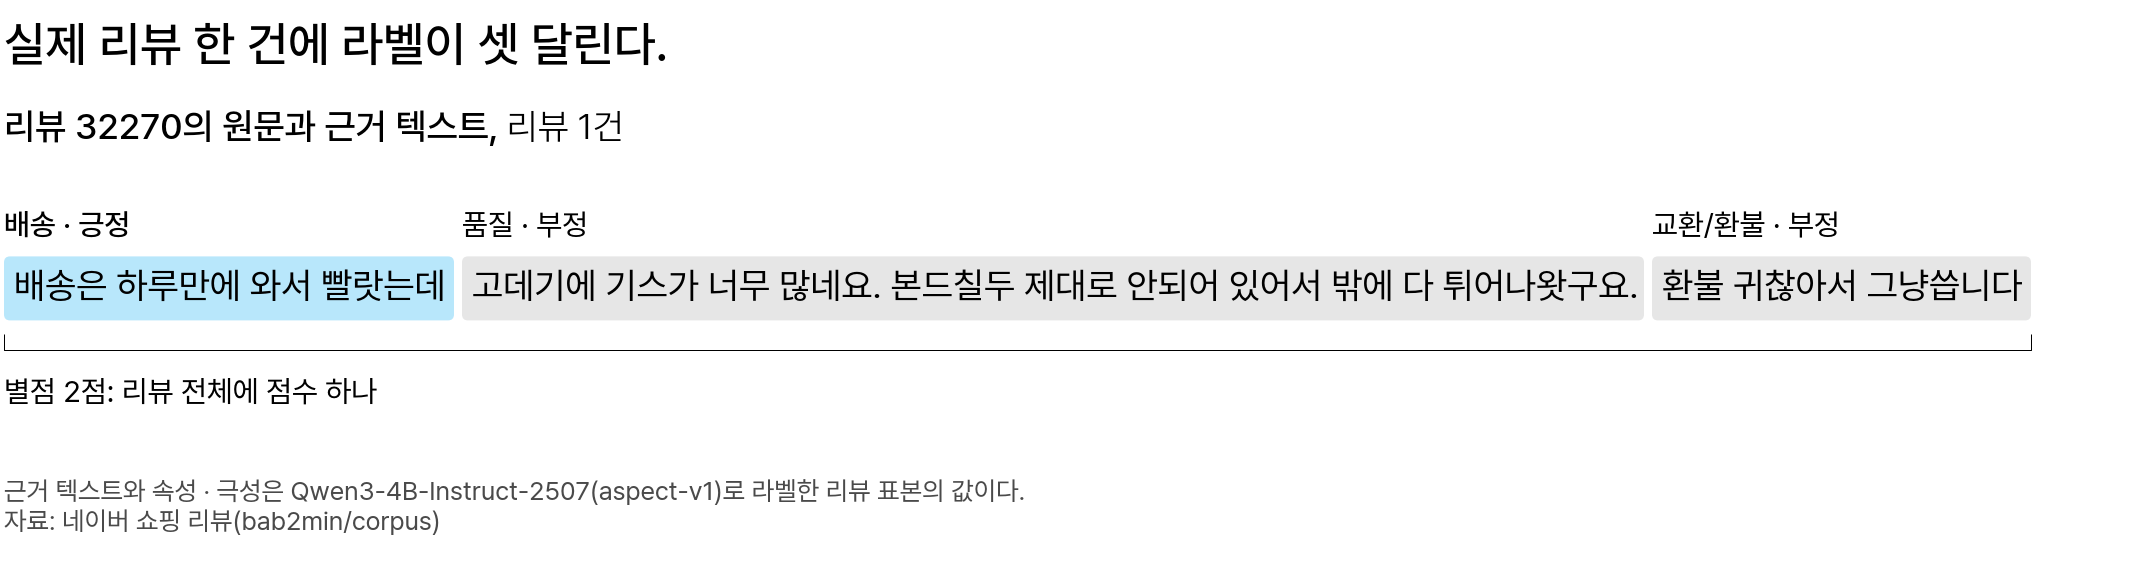

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로로 이어진 글 한 줄이 별점 2점 리뷰 32270 의 원문 전체다. 바탕을 칠한 세 곳이 근거 텍스트이고, 위 글자는 그 라벨의 속성 · 극성이다. 하늘색은 극성이 별점과 반대인 배송 · 긍정 라벨이다. 아래 선은 별점이 리뷰 전체에 걸린 점수 하나라는 표시다</em></p>

### LLM 출력 검증과 비율의 분모 [필수]

aspect-v1 시스템 프롬프트로 받은 출력은 모델마다 따로 검증했습니다. 작은 모델일수록 형식 실패가 얼마나 늘어나는지 보려고 Qwen2.5-0.5B 의 출력도 받았습니다.

- Qwen2.5-0.5B-Instruct 의 출력 2,000건: 같은 표본의 앞 2,000건에서 받은 출력입니다. 같은 시스템 프롬프트로 한 번씩 받았고 재시도는 하지 않았습니다. 가중치가 약 5억 개인 작은 모델입니다.
- Qwen3-4B 의 출력 1,000건: 라벨에 쓴 모델입니다. 4B 는 가중치 약 40억 개를 뜻합니다.
- 후보 모델 3개의 출력 100건씩: 라벨에 쓸 모델을 고를 때 썼습니다.

> **[예측] Qwen2.5-0.5B 가 같은 프롬프트로 2,000건을 한 번씩 생성했을 때, 스키마를 통과한 출력은 몇 % 일까요?**
>
> 1. 약 90%
> 2. 약 60%
> 3. 약 40%
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 셋째 보기 「약 40%」입니다. 2,000건을 파싱과 스키마 검증으로 검사한 결과입니다.

| 결과 | 건수 | 비율 |
|---|---:|---:|
| JSON 파싱 실패 | 156 | 7.8% |
| 파싱은 됐지만 스키마 실패 | 1,028 | 51.4% |
| 스키마 통과 | 816 | 40.8% |
| 합 | 2,000 | 100.0% |

실패한 출력 대부분은 JSON 으로는 읽히지만 스키마 검증을 통과하지 못합니다. 검사 결과마다 출력을 하나씩 골랐습니다(모델이 쓴 글은 필요한 부분만 옮김).

| 리뷰 | 모델이 쓴 글 | 검사 결과 |
|---|---|---|
| 리뷰 165395 | `{… "aspect":"시원함", … "evidence":"물론"]}]}` | 파싱 실패 |
| 리뷰 13473 | `{… "aspect":"편의제", "polarity":"긍정", …}` | 스키마 실패 |
| 리뷰 961 | `{… "aspect":"사이즈", "polarity":"부정", "evidence":"사이즈가 안맞아요"}]}` | 스키마 통과 |

- 리뷰 165395 는 예시 리뷰 6 처럼 라벨 항목의 중괄호를 닫기 전에 `]` 가 나와 JSON 으로 읽을 수 없습니다.
- 리뷰 13473 의 원문은 「펜으로 되어있어서 쓰기 편해요」 한 문장입니다. 모델은 코드북에 없는 속성 이름 「편의제」를 지어냈습니다.
- 리뷰 961 은 근거 텍스트 「사이즈가 안맞아요」도 원문에 있습니다.

**환각**(hallucination, 할루시네이션)은 없는 값을 그럴듯하게 지어내는 현상입니다. 바이브 데이터 분석 과목에서 보았습니다. 「편의제」가 그 예입니다. 그래서 작은 모델의 출력은 파싱이 되더라도 값까지 확인하기 전에는 집계할 수 없습니다.

스키마를 통과한 816건에는 (속성, 극성) 라벨이 모두 1,168개 있습니다. 리뷰 한 건에 라벨이 여럿일 수 있어 라벨 수가 출력 수보다 많습니다. 이 라벨들의 근거 텍스트는 원문에 있을까요?

> **[예측] 이 1,168개 가운데 근거 텍스트가 원문에 없는 라벨은 얼마일까요?**
>
> 1. 5% 미만
> 2. 약 4분의 1
> 3. 절반 넘게
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 셋째 보기 「절반 넘게」입니다. 라벨 1,168개 가운데 641개(54.9%)의 근거 텍스트가 원문에 없었습니다.

리뷰 49802 가 한 예입니다.

> 원문: 「이제품이 국내와 맞지않아요 잘 살펴보시고 구매하세요」
>
> 근거 텍스트: 「제품 자체의 상태와 성능(불량, 마감, 내구성, 맛·신선도, 성능, 디자인)」

이 근거 텍스트는 위 프롬프트에 쓴 품질의 정의를 그대로 옮긴 글입니다. 근거 텍스트에는 허용 값 목록이 없어, 이런 글도 스키마를 통과합니다. 스키마를 통과한 라벨도 근거 텍스트가 원문에 있는지 따로 확인합니다.

**라벨에 쓴 Qwen3-4B 의 출력은 단계마다 어떻게 나뉘었나요?**

Qwen3-4B 의 리뷰 1,000건은 예시 리뷰 10건과 같은 검증 4단계를 거쳤습니다. temperature 는 0, 재시도 상한은 1회입니다.

```text
보낸 리뷰 1,000건
  ↓ ① 파싱 · ② 스키마 검증
첫 시도 통과 873건 · 형식을 어긴 127건
  ↓ ③ 어긴 127건만 한 번 재시도
재시도 통과 108건 · 라벨 실패 19건
→ 통과한 리뷰 873 + 108 = 981건, 라벨 1,467개
  ↓ ④ 근거 텍스트 확인
근거 확인 1,431개 · 보류 36개(2.45%)
```

- 형식을 어긴 출력은 재시도로 대부분 통과했지만 근거가 없는 라벨은 ④에서야 걸러졌습니다.
- 근거 확인 비율은 1,431 ÷ 1,467 ≈ 0.975 입니다.

보류한 라벨 36개 가운데 하나가 리뷰 6171 입니다.

> 원문: 「굉장히약합니다」
>
> Qwen3-4B 의 근거 텍스트: 「매우약합니다」

뜻은 같지만 원문을 고친 글이라 원문의 부분 문자열이 아닙니다. 예시 리뷰 2 의 「뚜껑이 샌다」처럼 이 라벨은 보류됩니다.

같은 프롬프트로 받은 첫 출력에서 Qwen3-4B 는 873건(87.3%)이 스키마를 통과했습니다. Qwen2.5-0.5B 는 40.8% 로, 작은 모델에서 형식 실패가 크게 늘었습니다.

재시도는 형식을 고치지만 라벨의 뜻까지 바로잡지는 않습니다. 리뷰 71684(별점 5점)는 디자인과 가성비를 칭찬한 리뷰입니다.

> 「좋습니다 현존 최고 디자인 가성비 안전화입니다」

```text
첫 시도: (디자인, 긍정) · (가격, 긍정)
  → 「디자인」이 허용 목록 밖이라 스키마 실패, 재시도
재시도: (가격, 긍정)
  → 통과, 집계에 쓰는 라벨은 (가격, 긍정) 1개
```

예시 리뷰 9 는 재시도에서 「디자인」이 품질로 바뀌었습니다. 리뷰 71684 는 디자인 긍정을 품질로 바꾸지 않고 빼서, 품질 긍정 하나가 집계에서 사라졌습니다. 재시도하면 형식은 고쳐지지만 라벨이 빠질 수 있습니다.

첫 시도에 실패한 127건 가운데 가장 많은 79건은 리뷰 전체 극성 `overall` 에 허용 값 밖의 「중립」을 썼습니다. 그다음으로 많은 실패는 71684 처럼 코드북에 없는 속성 이름을 쓴 경우입니다. 가장 많이 나온 세 이름의 라벨은 모두 32개입니다.

| 출력의 속성 이름 | 라벨 수 | 그 단어가 있는 포함 기준 |
|---|---:|---|
| 디자인 | 17 | 품질 |
| 포장 | 9 | 배송 |
| 판매자 응대 | 6 | 기타 |

세 이름 모두 포함 기준에 있던 단어를 그대로 속성 이름으로 쓴 것입니다. aspect-v1 에는 이를 막을 제외 기준이 없었습니다.

다음 프롬프트 버전에서는 「디자인은 품질에 속하고 따로 속성 이름으로 쓰지 않는다」 같은 제외 기준을 추가합니다. 그 뒤 이런 실패가 줄어드는지 확인합니다.

**첫 시도 통과율이 가장 높은 모델을 고르면 될까요?**

Qwen3-4B 는 후보 모델 3개 가운데에서 골랐습니다. 세 모델에 리뷰 표본의 앞 100건을 보냈고, 프롬프트 aspect-v1 · temperature 0 · 재시도 1회는 모두 같습니다.

**첫 시도 통과율**은 첫 시도에 스키마를 통과한 출력의 비율이고, **재시도 뒤 통과율**은 재시도 한 번 뒤의 비율입니다.

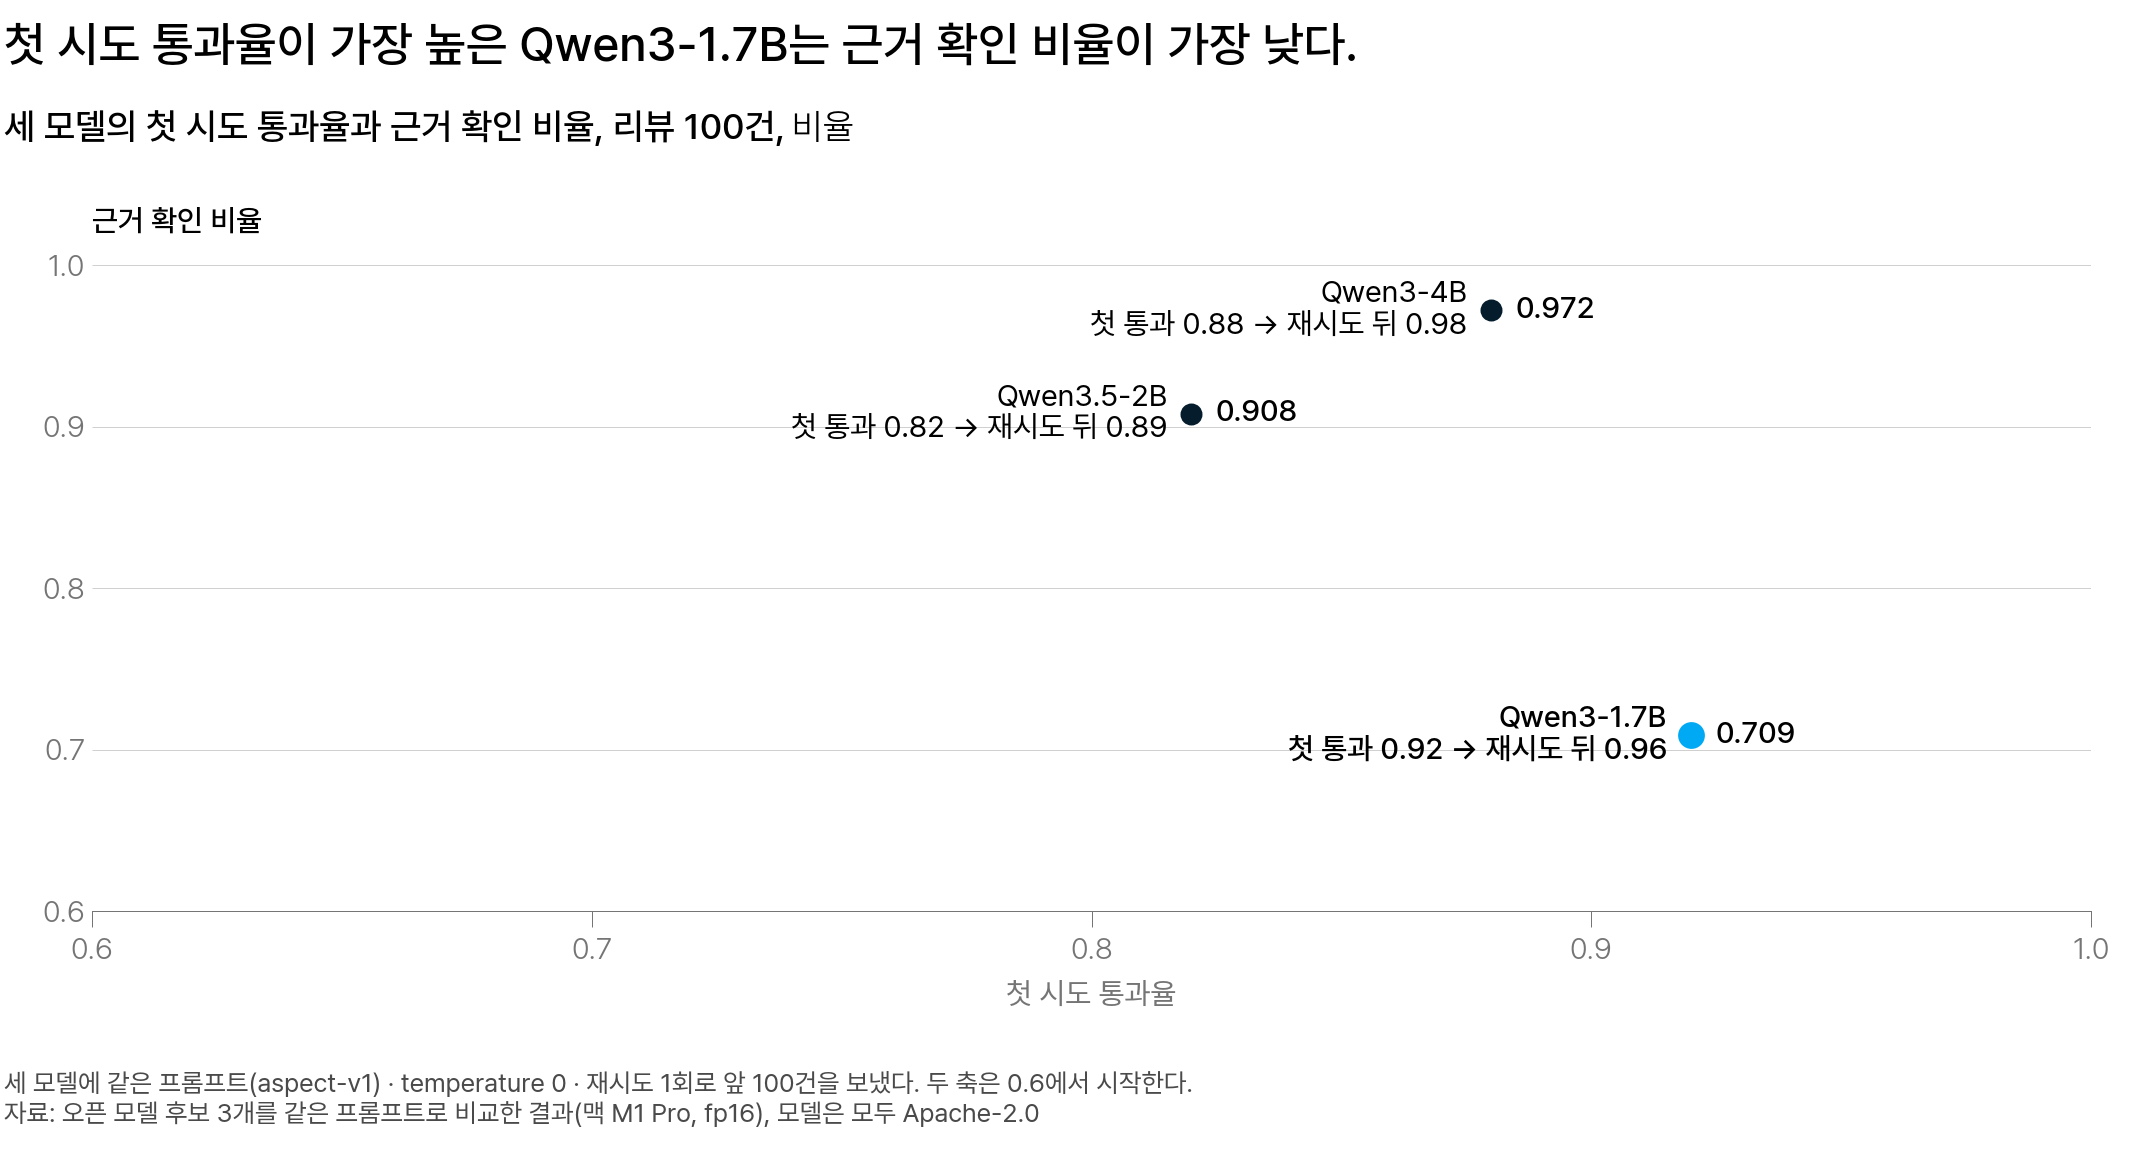

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 점 하나가 모델 하나다. 가로축은 첫 시도 통과율, 세로축은 근거 확인 비율이고 두 축 모두 0.6 에서 시작한다. 점 왼쪽 글자는 첫 시도 통과율에서 재시도 뒤 통과율로 바뀐 값이고, 점 오른쪽 수는 근거 확인 비율이다. 하늘색 점이 Qwen3-1.7B 다</em></p>

- 첫 시도 통과율만 보면 Qwen3-1.7B 를 고르게 됩니다. 그런데 이 모델은 라벨 10개 가운데 약 3개의 근거가 원문에 없습니다.
- 실제 라벨링은 실패한 출력을 한 번 재시도하므로, 형식은 재시도 뒤 통과율로 비교합니다. 이 기준으로는 Qwen3-4B 가 가장 높습니다.

Qwen3-4B 는 재시도 뒤 통과율 0.98 과 근거 확인 비율 0.972 가 모두 가장 높아, 라벨에 쓸 모델로 골랐습니다. 0.972 는 앞 100건에서 구한 값이라 1,000건의 0.975 와 조금 다릅니다.

**품질 부정 비율은 무엇으로 나누었나요?**

품질 부정 비율은 「3. LLM 출력 검증」의 식대로 구했습니다. 분자는 근거가 확인된 품질 부정 라벨이 있는 리뷰 수이고 분모는 보낸 리뷰 수입니다.

```text
품질 부정 비율 = 358건 ÷ 보낸 1,000건 = 35.8%
```

**분자는 왜 라벨 수가 아니라 리뷰 수인가요?**

리뷰 51225 에는 품질 부정 라벨이 2개 있습니다.

> 「불량품 왔어요. 딸아이 귀뚫다 지옥맛을 봤네요. 추천 안해요.」

근거 텍스트는 「불량품 왔어요」와 「딸아이 귀뚫다 지옥맛을 봤네요」입니다. 예시 리뷰 9 처럼 라벨이 여럿이어도 이 리뷰는 품질 부정 리뷰 한 건입니다.

```text
분자가 라벨 수일 때:  근거가 확인된 품질 부정 라벨 470개 ÷ 1,000 = 47.0%
분자가 리뷰 수일 때:  그 라벨이 있는 리뷰 358건 ÷ 1,000 = 35.8%
```

분자를 라벨 수로 두면 47.0% 로, 리뷰 수로 둘 때보다 11.2%p 커집니다. 불만을 여러 번 쓴 리뷰가 더 크게 반영되기 때문입니다.

**라벨 실패 19건은 어떻게 했나요?**

분모에 남겼습니다. 예시 리뷰 6 처럼 라벨 실패 리뷰는 불만이 있는지 모릅니다. 보낸 수로 나누면 이 리뷰들에 불만이 없다고 보는 셈입니다. 모델이나 재시도 횟수가 바뀌어도 같은 분모로 비교하려고 이렇게 정했습니다(「3. LLM 출력 검증」).

<details class="lms-extra"><summary>더 깊이 — 두 분모로 구한 품질 부정 비율</summary>

라벨 실패를 뺀 분모와, 재시도를 하지 않은 경우(상한 0회)도 계산했습니다. 분자는 근거가 확인된 품질 부정 리뷰입니다.

| 재시도 상한 | 분모 | 계산 | 품질 부정 비율 |
|---|---|---|---:|
| 0회 | 보낸 리뷰 1,000건 | 329 ÷ 1,000 | 32.9% |
| 0회 | 라벨 실패 127건을 뺀 873건 | 329 ÷ 873 | 37.7% |
| 1회 | 보낸 리뷰 1,000건 | 358 ÷ 1,000 | 35.8% |
| 1회 | 라벨 실패 19건을 뺀 981건 | 358 ÷ 981 | 36.5% |

재시도로 라벨 실패가 줄면, 두 분모로 구한 비율의 차이도 4.8%p 에서 0.7%p 로 줄어듭니다.

</details>

### 리뷰 20만 건의 비용 [선택]

팀 라운드에서 리뷰 20만 건을 어디서 라벨할지 정하려면 API 비용과 오픈 모델의 시간을 알아야 합니다. 「4. API 로 라벨해도 되는가」의 비용 식에 리뷰 20만 건의 실제 한 건 평균 토큰 수를 대입한 결과입니다.

```text
한 건 평균: 시스템 프롬프트 386 · 리뷰 입력 30.27 · 출력 52.22토큰
API(gpt-5-nano): 표준 8.34달러 · 배치 4.17달러
오픈 모델(Qwen3-4B): 0.88초 × 200,000건 = 176,000초 ≈ 49시간
```

0.88초는 Colab T4 한 대에서 속성 JSON 한 건에 걸린 시간입니다(라벨을 만든 맥 M1 Pro 에서는 약 5초).

<details class="lms-extra"><summary>자세히 — 비용 계산</summary>

출력 52.22토큰은 Qwen3-4B 첫 시도 JSON 의 평균이고, gpt-5-nano 도 같은 JSON 을 낸다고 본 어림입니다. 20만 건의 비용을 ①에서 ⑧까지 차례로 계산합니다.

| 차례 | 계산 | 값 |
|---|---|---:|
| ① 시스템 프롬프트 입력 합 | 200,000 × 386 | 77,200,000 |
| ② 리뷰 입력 합 | 20만 건의 「리뷰: …」 토큰 수를 모두 더함 | 6,054,561 |
| ③ 입력 합 | ① + ② | 83,254,561 |
| ④ 출력 합 | Qwen3-4B 첫 시도 출력의 평균 토큰 수 52.218 × 200,000 | 10,443,600 |
| ⑤ 입력 비용 | 83,254,561 × 0.05 ÷ 10⁶ | 4.16 |
| ⑥ 출력 비용 | 10,443,600 × 0.40 ÷ 10⁶ | 4.18 |
| ⑦ 표준 합계 | ⑤ + ⑥ | 8.34 |
| ⑧ 배치 합계 | ⑦ × 0.5 | 4.17 |

④의 평균 52.218 을 소수 둘째 자리까지 반올림한 값이 52.22 입니다. ②를 건수로 나누면 약 30.27토큰으로 리뷰 입력 평균과 같습니다. 이 값은 「리뷰: 」를 포함한 토큰 수이고, 본문만은 평균 8.56어절 · 27.41토큰입니다.

</details>

리뷰 본문은 평균 8.56어절로 짧습니다. 그래서 「4. API 로 라벨해도 되는가」의 가정처럼 어절로 어림해도 합계가 거의 같습니다(8.12 대 8.34달러). 리뷰가 길면 크게 달라지므로 계산은 토큰으로 합니다.

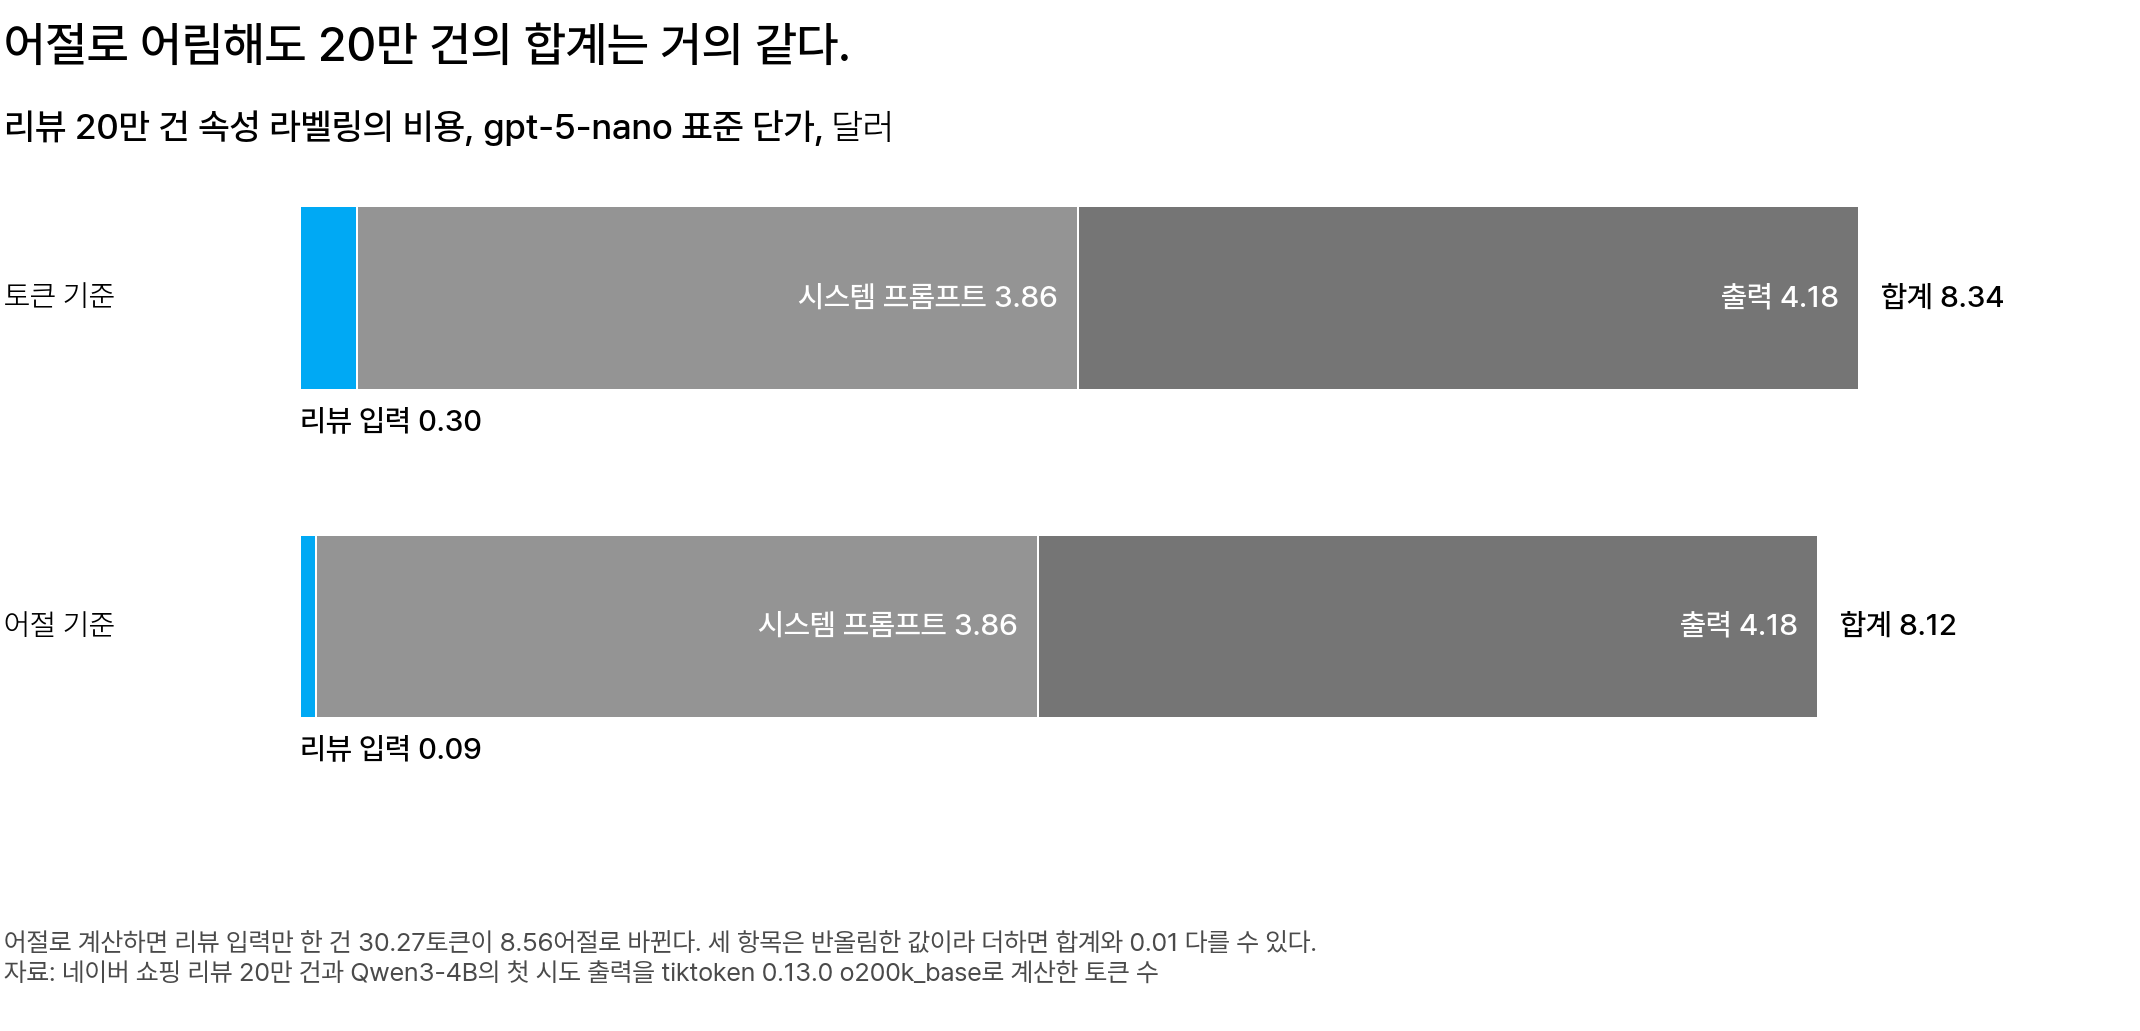

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 두 막대는 같은 20만 건의 비용을 두 셈법으로 계산한 것이다. 가로축은 비용(달러)이고, 위 막대는 토큰, 아래 막대는 어절로 계산했다. 하늘색이 리뷰 입력이고, 회색인 시스템 프롬프트 · 출력은 두 막대에서 길이가 같다. 막대 오른쪽의 수가 합계다</em></p>

### 리뷰 전체 극성과 속성별 부정 비율 [필수]

**리뷰 전체 극성은 별점과 얼마나 일치하나요?**

별점과 비교하는 리뷰 전체 극성은 선택형 극성으로 따로 구했습니다. JSON 의 `overall` 에는 허용 값 밖의 「중립」이 나오기 때문입니다.

선택형 극성은 형식 실패가 없어 리뷰 표본 2만 건 모두에 있습니다. 예시 리뷰 6 처럼 라벨 실패인 리뷰도 선택형 극성은 있습니다.

<details class="lms-extra"><summary>더 깊이 — 두 리뷰 전체 극성의 비교</summary>

모델을 고를 때 쓴 앞 100건에서는 2건이 재시도 뒤에도 「중립」이었습니다. 이 100건에서 별점 극성과 일치하는 리뷰의 비율은 선택형 극성이 0.92, JSON 의 `overall` 이 0.939 였습니다. 일치하는 리뷰는 둘 다 92건입니다.

```text
선택형 극성:     92 ÷ 100 = 0.92
JSON 의 overall: 92 ÷ 98  ≈ 0.939  (「중립」 2건은 분모에서 빠짐)
```

JSON 쪽은 분모가 작아서 높아 보입니다. 그래서 빠지는 리뷰가 없는 선택형 극성을 씁니다.

</details>

「5. 별점과 비교한 결과」처럼 두 극성으로 나눈 표는 앞 200건으로 구했습니다. 이 리뷰들은 실습에서 모델을 다시 호출해 확인할 수 있습니다.

| | 별점 부정(1 · 2점) | 별점 긍정(4 · 5점) | 합 |
|---|---:|---:|---:|
| LLM 부정 | **106** | 8 | 114 |
| LLM 긍정 | 6 | **80** | 86 |
| 합 | 112 | 88 | 200 |

굵은 두 수가 극성이 일치하는 리뷰라, 일치율은 (106 + 80) ÷ 200 = 0.93 입니다.

별점 부정이 112건으로 더 많아, 리뷰를 읽지 않고 늘 「부정」이라고 답해도 일부는 일치합니다.

```text
늘 「부정」이라고만 답할 때: 112 ÷ 200 = 0.56
LLM 의 선택형 극성, 200건: 186 ÷ 200 = 0.93
LLM 의 선택형 극성, 2만 건: 0.92
```

한쪽으로만 답할 때보다 0.37 높고 2만 건에서도 거의 그대로입니다. Colab T4 로 같은 200건을 다시 라벨해도 0.93 으로 같았습니다. 다만 이 자료에는 판단이 갈리기 쉬운 3점 리뷰가 없습니다. 3점이 있는 자료에서는 일치율이 더 낮을 수 있습니다.

**불일치 14건에서는 어느 쪽이 틀렸나요?**

| 리뷰 | 별점 | LLM | 원문 |
|---:|---:|---|---|
| 8761 | 1 | 긍정 | 배송빠르군요 잘쓸께요 굿 |
| 84791 | 5 | 부정 | 택배는 진짜 느리네요 |
| 39192 | 5 | 부정 | 삼겹살 구워먹을때 냄새가 너무 심하게 나서 구매했어요 |

- 8761 과 84791 은 예시 리뷰 7 처럼 별점이 본문과 반대입니다. LLM 은 본문과 맞는데도 불일치가 됩니다.
- 39192 는 LLM 이 틀린 쪽입니다. 냄새는 제품을 산 이유이지, 제품의 흠이 아닙니다.

별점이 틀린 리뷰도 LLM 이 틀린 리뷰도 있어, 일치율을 LLM 의 정확도로 볼 수는 없습니다.

**속성 라벨도 별점으로 확인할 수 있나요?**

속성 라벨이 있는 리뷰 1,000건에서는 별점과 부정 라벨이 맞지 않는 리뷰가 135건입니다.

| 별점 | 리뷰 수 | 맞지 않는 리뷰 | 부정 라벨 |
|---|---:|---:|---|
| 4 · 5점 | 482 | 70 | 근거가 확인된 부정 라벨이 있음 |
| 1 · 2점 | 518 | 65 | 근거가 확인된 부정 라벨이 없음(라벨 실패 10건 포함) |

별점은 리뷰 전체에 매긴 수 하나라, 별점으로는 속성 라벨이 맞는지 확인할 수 없습니다.

**어느 속성의 부정 비율이 가장 높나요?**

같은 1,000건으로 속성 6개의 부정 비율과 95% 구간을 구했습니다. 구간의 식은 「5. 별점과 비교한 결과」와 같고, $n$ 은 보낸 리뷰 1,000건입니다. 품질은 0.358 을 대입합니다.

$$
1.96 \sqrt{\frac{0.358 \times 0.642}{1{,}000}} = 0.030
$$

그래서 품질 부정 비율의 95% 구간은 35.8% ± 3.0%p 입니다.

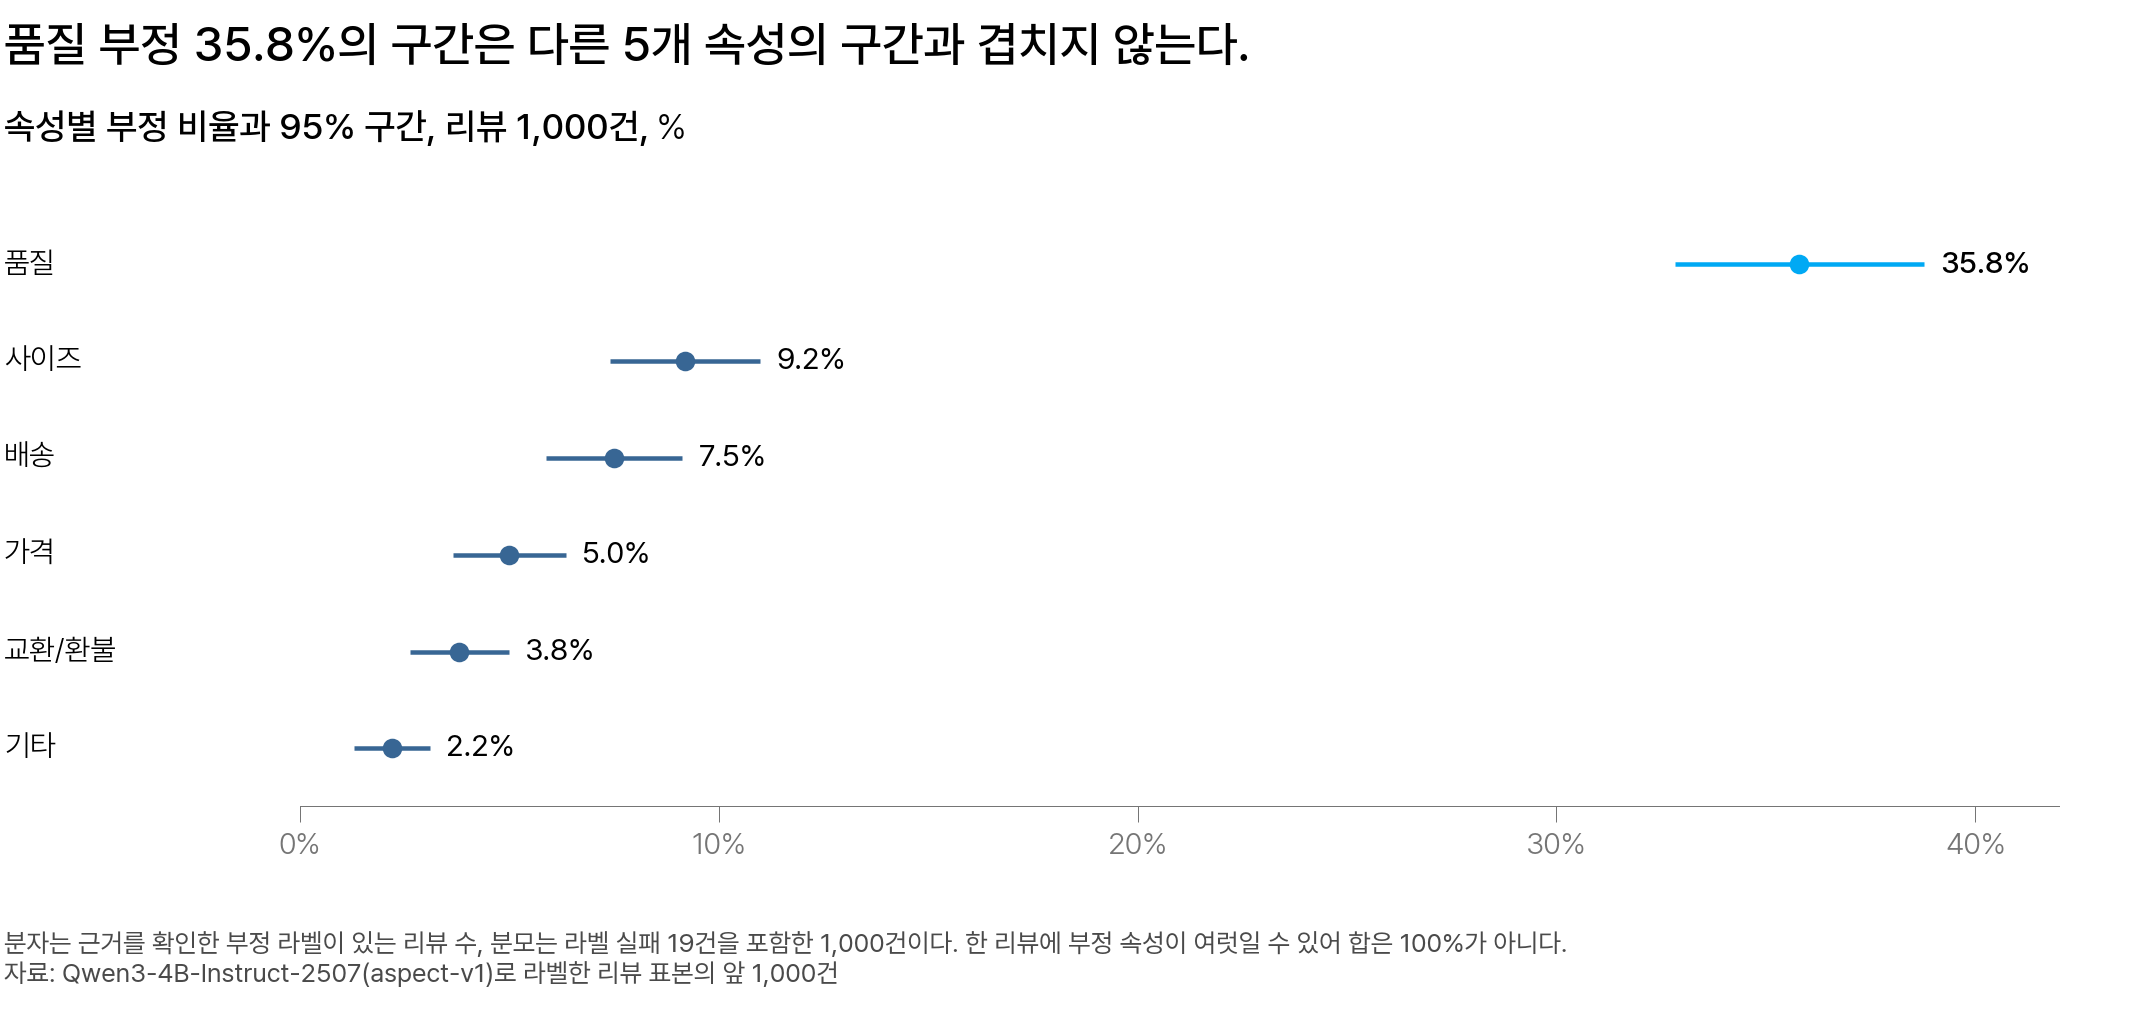

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 부정 비율이다. 점은 리뷰 1,000건에서 구한 속성별 부정 비율이고, 점을 지나는 가로선은 95% 구간이다. 하늘색이 품질이다</em></p>

- 품질의 구간 아래 끝 32.8% 는 나머지 속성 5개의 구간 위 끝보다 큽니다. 그래서 품질이 가장 많다는 결론은 다른 1,000건을 골라도 바뀌기 어렵습니다.
- 사이즈의 구간 7.4～11.0% 와 배송의 구간 5.9～9.1% 는 겹칩니다. 「5. 별점과 비교한 결과」의 100건 가정에서처럼 둘의 순위는 정하지 않습니다.

**품질 부정 35.8% 는 어떤 불만인가요?**

품질은 불량 · 마감부터 맛 · 신선도 · 디자인까지 포함한 속성입니다.

- 리뷰 51225 의 「불량품 왔어요」는 불량입니다.
- 리뷰 44334 의 「약해 보이긴한데」는 내구성입니다.
- 리뷰 20만 건에는 식품 리뷰도 있어, 맛에 대한 불만도 품질에 속합니다.

그래서 품질 부정 비율은 여러 종류의 불만을 합친 비율입니다. 품질 안에서 무엇이 많은지 알려면 코드북에서 품질을 나눠 다시 라벨해야 합니다.

<details class="lms-extra"><summary>더 깊이 — 표본 2만 건의 오차 한계</summary>

표본 2만 건 모두에 속성 라벨이 있다면 오차 한계 식의 $n$ 이 20,000 이 됩니다. 비율이 지금과 같다고 보고 품질의 0.358 을 대입합니다.

$$
1.96 \sqrt{\frac{0.358 \times 0.642}{20{,}000}} \approx 0.0066
$$

품질의 오차 한계는 ±3.0%p 에서 ±0.66%p 로 줄어듭니다. 부정 비율이 가장 낮은 기타(2.2%)는 ±0.9%p 에서 ±0.20%p 로 줄고, 나머지 속성은 이 둘 사이입니다.

하지만 속성 라벨은 앞 1,000건에만 있습니다. 구간을 그만큼 좁히려면 나머지 리뷰에도 속성 라벨을 받아야 합니다.

</details>

**비율을 쓰기 전에 무엇을 확인하나요?**

비율의 분모와 분자는 검증 단계에서 리뷰와 라벨이 어떻게 나뉘었는지로 정해집니다. 아래 그림에서 단계마다 빠지는 부분을 다시 확인합니다.

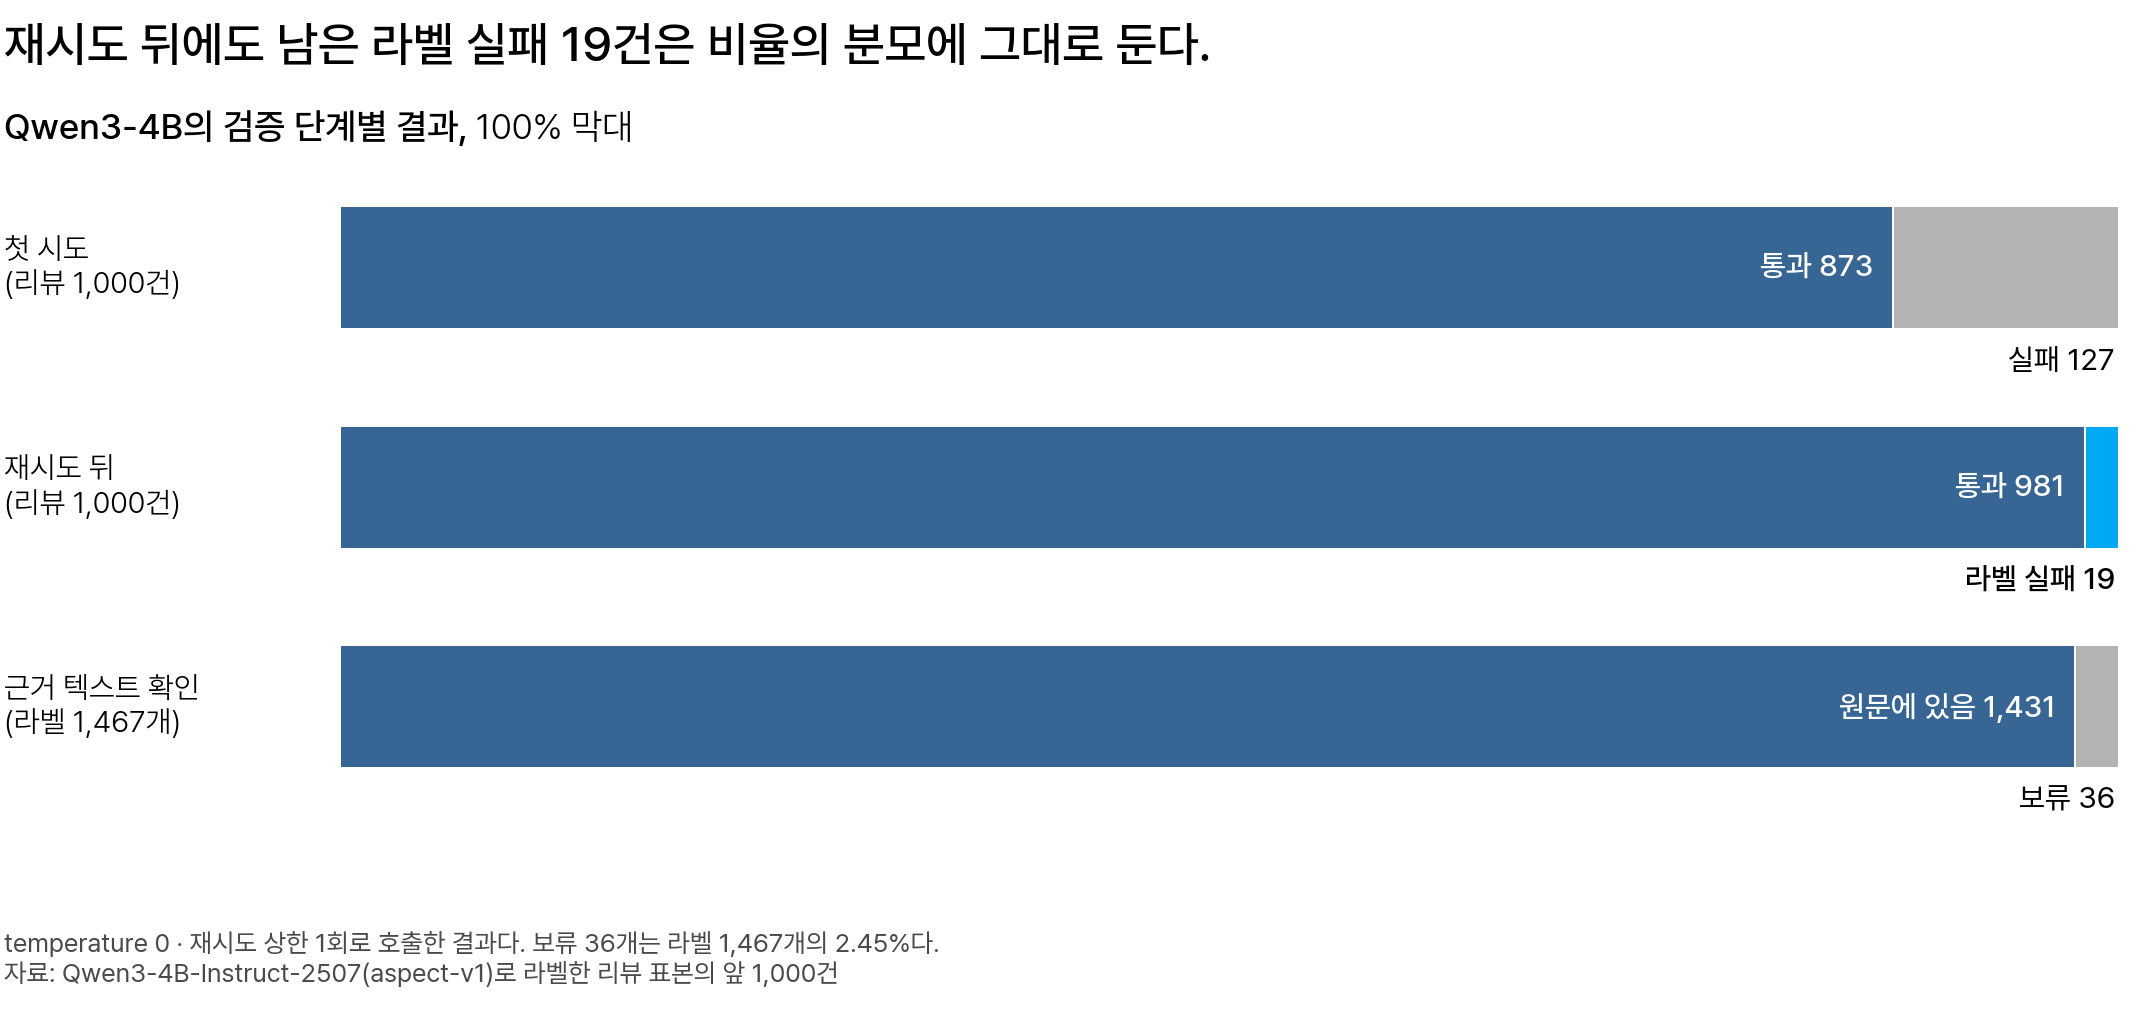

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 막대 하나가 Qwen3-4B 의 검증 단계 하나이고, 막대 길이는 단계마다 전체를 100% 로 한 비율이다. 위 두 막대는 리뷰 1,000건, 셋째 막대는 재시도 뒤 통과한 리뷰 981건의 라벨 1,467개다. 회색은 그 단계를 통과하지 못한 부분이고, 하늘색은 재시도 뒤에도 형식을 어긴 라벨 실패다. 비율의 분모는 둘째 막대 전체다</em></p>

비율을 쓰기 전에는 분모와 보류한 라벨, 버전 기록을 확인합니다.

1. 분모가 라벨 실패를 포함한 보낸 리뷰 수인가(1,000건, 라벨 실패 19건 포함)
2. 근거 텍스트가 원문에 없는 라벨을 뺐는가(라벨 1,467개 가운데 보류 36개)
3. 모델 이름 · 모델 버전 · 프롬프트 버전을 기록했는가

이 1,000건은 아래 모델과 프롬프트로 라벨했습니다.

- 모델 이름: Qwen3-4B-Instruct-2507(2507 은 버전이 아니라 이름의 일부)
- 모델 버전: cdbee75f(모델 파일이 바뀌면 달라지는 Hugging Face 저장소의 값)
- 프롬프트 버전: aspect-v1

모델과 프롬프트 버전을 모르면 다음 분기나 다른 모델의 비율과 비교할 수 없습니다.

<details class="lms-extra"><summary>더 깊이 — 라벨을 만든 기기</summary>

위 목록에는 라벨을 만든 기기가 없습니다. 대신 맥 M1 Pro 에서 라벨한 앞 200건을 Colab T4 로 다시 라벨해 비교했습니다. 라벨 실패가 3건에서 2건으로 한 건만 달랐습니다. 기기를 바꾸면 이처럼 같은 리뷰 몇 건을 다시 라벨해 비교합니다.

라벨은 맥 M1 Pro 에서 fp16 으로 만들었습니다. fp16 은 수를 16비트로 줄여 계산하는 방식입니다. 선택형 극성은 T4 에서 한 건에 0.05초가 걸렸습니다.

</details>

다만 리뷰 8761 처럼 근거 텍스트가 원문에 있어도 틀린 라벨이 있어, 라벨이 코드북에 맞는지는 원문을 읽어야 압니다.

<div class="lms-summary">

**정리**

리뷰 1,000건에서 품질 부정이 35.8% 로 가장 많고, 사이즈와 배송은 구간이 겹칩니다. 분모는 라벨 실패 19건을 포함한 1,000건입니다. 근거 텍스트가 원문에 없는 라벨 36개는 집계에서 빠지고, 그 리뷰는 분모에 남습니다.

**할 일**

- 결과 파일에 비율과 라벨 실패 건수, 모델 이름 · 모델 버전 · 프롬프트 버전을 기록합니다
- 다음 프롬프트 버전에는 코드북의 제외 기준을 추가합니다
- 품질 안에서 무엇이 많은지 보려면 코드북에서 품질을 나눠 다시 라벨합니다

라벨이 사람의 판단과 얼마나 맞는지는 사람이 라벨한 무작위 표본과 비교해야 압니다.

</div>

> **[문제] 스키마를 통과한 출력만 분모로 둔 집계**
>
> 전임 담당자는 리뷰 2,000건을 보냈고 스키마를 통과한 816건만 분모로 두어 「사이즈 부정 15.93%」를 집계했습니다. 이 비율의 분모는 무엇이어야 하는지 적고, 통과한 건만 분모로 두면 비율이 커지는지 작아지는지 한 문장으로 적어 보세요.

### 팀 라운드: 리뷰 20만 건을 어디서 라벨할 것인가 [필수]

아래 질문의 답은 수업에서 팀이 함께 정합니다. 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 리뷰 20만 건을 어디서 라벨할 것인가**
>
> 분석팀이 리뷰 20만 건에 속성 라벨을 낼 모델과 실행할 곳을 정해야 합니다. 운영팀은 다음 분기부터 속성별 부정 비율을 분기마다 받아 비교합니다. 세 모델의 값은 같은 코드북과 프롬프트로 리뷰 100건을 라벨한 결과입니다.
> 
> - **첫 시도 통과율(리뷰 100건)** Qwen3.5-2B 0.82, Qwen3-1.7B 0.92, Qwen3-4B 0.88
> - **재시도 뒤 통과율(리뷰 100건)** Qwen3.5-2B 0.89, Qwen3-1.7B 0.96, Qwen3-4B 0.98
> - **근거 확인 비율(리뷰 100건)** Qwen3.5-2B 0.908, Qwen3-1.7B 0.709, Qwen3-4B 0.972
> - **Qwen3-4B 로 20만 건** Colab T4 한 대로 약 49시간
> - **gpt-5-nano(OpenAI) 배치로 20만 건** 4.17달러(조회 2026-09-25), 이 코드북으로 구한 근거 확인 비율은 없음
> 
> 팀 안에서 의견이 3가지로 나뉘었습니다.
> 
> - **관점 A: Qwen3-4B 로 회사 GPU 에서 라벨한다.** 재시도 뒤 통과율과 근거 확인 비율이 세 모델 가운데 가장 높다. 고객 글이 회사 밖으로 나가지 않고, 분기마다 같은 모델 버전으로 라벨할 수 있다.
> - **관점 B: 데이터 정책 원문을 확인하고 비식별한 뒤 gpt-5-nano 배치로 보낸다.** 회사 GPU 를 쓰지 않고 적은 비용으로 끝난다. 근거 확인 비율이 없으니, 먼저 100건에 검증 4단계를 실행해 구한다.
> - **관점 C: Qwen3-1.7B 로 회사 GPU 에서 라벨한다.** 첫 시도 통과율이 세 모델 가운데 가장 높다. 근거 텍스트가 원문에 없는 라벨은 검증에서 보류되므로, 집계에 남는 라벨은 모두 근거가 확인된 것이다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.